# Семинар 6. Многоклассовая классификация. Метрики качества.

In [85]:
%matplotlib inline
import ast
import io
from pathlib import Path
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

SEED = 42
# thread_limit = threadpool_limits(limits=1)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11})

Рассмотрим задачу минимизации эмпирического риска
$$
\hat{f} \in \arg\min_{f}\dfrac{1}{N}\sum_{i=1}^N \mathcal{L}(y_i, f(x_i))
$$

Задача *мультиклассовой классификации* определяется множеством допустимых $y \in \mathcal{Y} = \{0, \ldots, K\}$ для $K > 1$. Важно, что конкретный $y_i$ является элементом множеста.

<img src = 'src/multilabel_banner.png' width = 2000>

### Линейная классификация

<details>
<summary><b>Напоминание: линейная классификация</b></summary>

Мы хотим минимизировать число ошибок классификатора, то есть

$$
\dfrac{1}{N} \sum_{i=1}^N \mathbb{I}[y_i \neq b(x_i)] → \min_{w}
$$
Для $y_i\in\{-1,+1\}$ и ненулевого отступа домножим на $y_i$:
$$
y_i \neq b(x_i) ⇒ y_i^2 \neq y_i b(x_i) ⇒ y_i b(x_i) \neq 1 ⇒ y_i(\langle w, x_i\rangle + w_{0}) < 0
$$
Величина $M_i = y_i(\langle w, x_i\rangle + w_{0})$ называется **отступом (margin)** классификатора.


*   отступ положителен, когда $sign(y_i) = sign(\langle w, x_i\rangle + w_{0})$, то есть класс угадан верно; при фиксированном $w\neq0$ расстояние до гиперплоскости равно $|M_i|/\|w\|$. Сам отступ не является вероятностью и зависит от масштаба весов;
*  отступ отрицателен, когда $sign(y_i) \neq sign(\langle w, x_i\rangle + w_{0})$ , то есть класс угадан неверно; при этом чем больше по модулю отступ, тем более сокрушительно ошибается классификатор.

Таким образом, задача линейной классификации
$$
\dfrac{1}{N} \sum_{i=1}^N \mathbb{I}[M_i < 0] → \min_{w} \tag{1}
$$

<details>
<summary><b>В чем проблема минимизации функции потерь (1)?</b></summary>

Функция $\mathbb{I}[M_i < 0]$ является кусочно-постоянной, поэтому её производные равны нулю везде, где существуют. Мы можем заменить её суррогатной функцией потерь. Hinge-loss мажорирует 0–1 потерю, а перцептронная потеря — нет: при $M_i=-0.1$ она равна $0.1<1$. Обе функции имеют излом и допускают использование субградиентов.


*   Перцептрон: $\max\{0, -M_i\}$
*   Hinge-Loss: $\max\{0, 1 - M_i\}$

![margin_loss](src/margin_loss.webp)

Помимо Hinge-функции потерь $\tilde{h}(M) = \max\{0, 1 - M\}$ (линейный метод опорных векторов), на семинаре будет рассмотрен log-loss $\tilde{h}(M) = \log(1 + e^{-M})$ (логистическая регрессия)
</details>
</details>

Однако зачем нужно на практике из линейной регрессии $r(x) = \langle w, x_i\rangle + w_{0}$ строить линейную классификацию $c(x) = sign(\langle w, x_i\rangle + w_{0})$, а затем аппроксимировать пороговую функцию потерь?

<details>
<summary><b>В чем проблема использования $r(x)$ с $MSE(r(x), y) = [r(x) - y]^2$?</b></summary>

* Во-первых, регрессия почти не штрафует за ошибки на объектах, которые лежат близко к разделяющей плоскости, но не с той стороны.
* Во вторых, ошибкой будет считаться предсказание, например, 5 вместо 1, хотя нам-то на самом деле не важно, какой у числа модуль, лишь бы знак был правильным.

Если визуализировать такое решение, то проблемы тоже вполне заметны:

![mse_as_classifier](src/mse_as_classifier.webp)

Описанные проблемы возникают несмотря на то, что в теории оптимальный $\hat{y}^\ast =  \arg\min_{\hat{y} \in \mathbb{R}}\mathbb{E}\left[(y^i - \hat{y}) \mid x\right]$ соответствует вероятности $\mathbb{P}\left(y^i = 1 \mid x\right)$. Т.е. с точки зрения оптимизации MSE является подходящей фунцией потерь.

Проблемы возникают из-за того, что $r(x) \in \mathbb{R}$. Давайте рассмотрим $\sigma(r(x)) \in (0, 1)$.

<details>
<summary><b>В чем проблема использования $\sigma(r(x))$ с $\mathcal{L}_{MSE}(\sigma(r(x)), y) = [\sigma(r(x)) - y]^2$?</b></summary>

Пусть $r(x) = z$ и $\sigma(z) = p$ ассмотрим градиент по логиту $z$
$$
\dfrac{\partial\mathcal{L}_{MSE}}{\partial z} = 2 * (p - y) * \dfrac{\partial\sigma(z)}{\partial z} = 2 * (p - y) * p (1 - p)
$$

Если правильный класс $y = +1$, а модель выдаёт $z = -10$, то $\sigma(z) \sim 4.5 * 10^{-5}$, т.е. она уверенно ошибается. Однако $\frac{\partial\mathcal{L}_{MSE}}{\partial z} \sim 9 * 10^{-5}$, т.е. градиент около нуля и $r(x)$ не штрафуется за неправильные решения.

Проблема состоит в том, что MSE с сигмоидой является невыпуклой
$$
\dfrac{\partial^2 \mathcal{L}_{MSE}}{\partial z^2} = 2 p* (1 - p)^2 (3p-1) < 0 \Rightarrow p < \dfrac{1}{3}
$$
Поэтому в области низких вероятностей градиент не соотносится с нашими наблюдениями.

</details>
</details>

## Сведение к бинарным задачам

### Один против всех (One-versus-All)

Обучим $K$ линейных классификаторов с сырыми оценками $g_1(x), g_2(x), \ldots, g_K(x)$ разделять свой класс от всех остальных
$$
g_k(x) = \langle w_k, x\rangle + w_{0k},\quad b_k(x)=sign(g_k(x)), \quad y \rightarrow y_k = 2\mathbb{I}[y = k] - 1
$$
Итоговый классификатор будет выдавать класс, соответствующий самому уверенному из бинарных алгоритмов:
$$
f(x) = \arg\max_{k\in\{1,\ldots , K\}} g_k(x)
$$

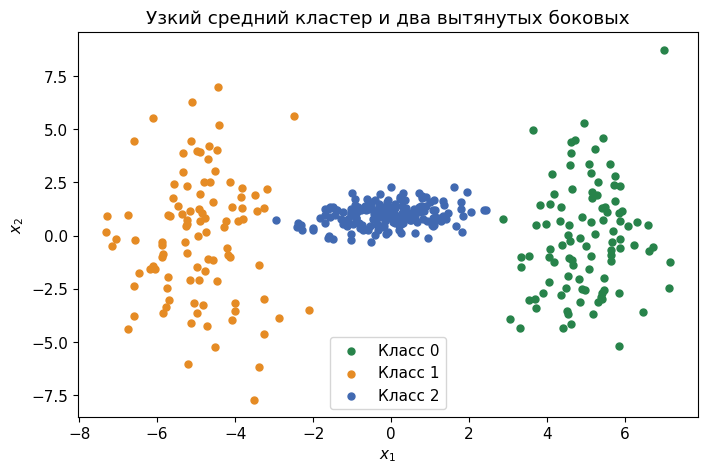

In [86]:
def create_synthetic_data(seed, multiplier=1):
    rng = np.random.default_rng(seed)
    centers = np.array([[5., 0.], [-5., 0.], [0., 1.]])
    scales = np.array([[1., 3.], [1., 3.], [1., .5]])
    counts = np.array([100, 100, 180]) * multiplier
    X = np.vstack([rng.normal(center, scale, size=(count, 2))
                   for center, scale, count in zip(centers, scales, counts)])
    y = np.repeat(np.arange(3), counts)
    order = rng.permutation(len(y))
    return X[order], y[order]


X, y = create_synthetic_data(SEED)
X_synthetic_test, y_synthetic_test = create_synthetic_data(SEED + 100, multiplier=20)
class_colors = ['#27834a', '#e58b24', '#4169b1']

fig, ax = plt.subplots(figsize=(8, 5))
for label, color in enumerate(class_colors):
    ax.scatter(*X[y == label].T, color=color, label=f'Класс {label}', s=25)
ax.set(xlabel='$x_1$', ylabel='$x_2$', title='Узкий средний кластер и два вытянутых боковых')
ax.legend()
plt.show()

В качестве мажорирующей функции отступа (1) возьмём Hinge-Loss:
$$
\dfrac{1}{N} \sum_{i=1}^N \max\{0, 1 - y_i(\langle w, x_i\rangle + w_0)\} → \min_{w}
$$
Один из допустимых субградиентов нерегуляризованной функции потерь:
$$
\nabla_w = \dfrac{1}{N} \sum_{i=1}^N \begin{cases}
0, & 1 - y_i(\langle w, x_i\rangle + w_0) \leqslant 0 \\
-y_ix_i, & 1 - y_i(\langle w, x_i\rangle + w_0) > 0
\end{cases}
$$
$$
\nabla_{w_0} = \dfrac{1}{N} \sum_{i=1}^N \begin{cases}
0, & 1 - y_i(\langle w, x_i\rangle + w_0) \leqslant 0 \\
-y_i, & 1 - y_i(\langle w, x_i\rangle + w_0) > 0
\end{cases}
$$

Проводим оптимизацию с помощью субградиентного спуска.
$$
w = w - \eta\nabla_w, \quad w_0 = w_0 - \eta\nabla_{w_0}
$$
В коде ниже `SGDClassifier` дополнительно использует регуляризацию L2 по умолчанию.

In [87]:
from sklearn.linear_model import SGDClassifier

sgd_parameters = dict(loss='hinge', learning_rate='constant', eta0=0.01,
                      alpha=0.001, max_iter=3000, tol=1e-5, random_state=SEED)
models_ova = []
for label in range(3):
    y_binary = np.where(y == label, 1, -1)
    # y = [0, 0, 1, 2, 0, ...]
    # y == label => [True, True, False, False, ...]
    model = SGDClassifier(**sgd_parameters).fit(X, y_binary)
    models_ova.append(model)
models = models_ova

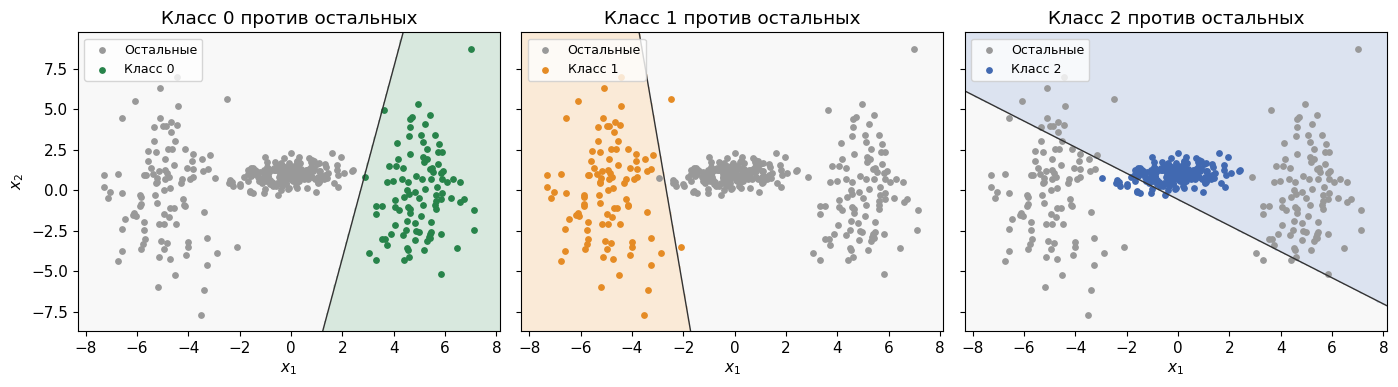

In [88]:
from itertools import combinations

pairs = [(0, 1), (0, 2), (1, 2)]


def make_grid(X):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 180),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 140))
    return xx, yy, np.c_[xx.ravel(), yy.ravel()]


def plot_binary_bound(X, y, models, mode='ova', target_pairs=None, colors=None,
                      highlight=None):
    colors = class_colors if colors is None else colors
    if mode == 'ava' and target_pairs is None:
        target_pairs = list(combinations(np.unique(y), 2))
    xx, yy, grid = make_grid(X)
    columns = 2 if len(models) == 4 else min(3, len(models))
    rows = (len(models) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(4.7 * columns, 4 * rows),
                             sharex=True, sharey=True, squeeze=False)
    for index, (model, ax) in enumerate(zip(models, axes.flat)):
        if mode == 'ova':
            groups = [(y != index, '#999999', 'Остальные'),
                      (y == index, colors[index], f'Класс {index}')]
            region_colors = ['#dddddd', colors[index]]
            title = f'Класс {index} против остальных'
        else:
            first, second = target_pairs[index]
            groups = [(y == second, colors[second], f'Класс {second}'),
                      (y == first, colors[first], f'Класс {first}')]
            region_colors = [colors[second], colors[first]]
            title = f'Класс {first} против класса {second}'
        scores = model.decision_function(grid).reshape(xx.shape)
        ax.contourf(xx, yy, scores > 0, levels=[-.5, .5, 1.5],
                    alpha=.18, cmap=ListedColormap(region_colors))
        if scores.min() < 0 < scores.max():
            ax.contour(xx, yy, scores, levels=[0], colors='#333333', linewidths=1)
        for mask, color, label in groups:
            ax.scatter(*X[mask].T, color=color, label=label, s=15)
        if highlight is not None:
            visible = np.logical_or.reduce([mask for mask, _, _ in groups])
            ax.scatter(*X[highlight & visible].T, facecolors='none', edgecolors='#222222',
                       s=60, linewidths=.8)
        ax.set(title=title, xlabel='$x_1$')
        ax.legend(fontsize=9, loc='upper left')
    for ax in axes.flat[len(models):]:
        ax.set_visible(False)
    for ax in axes[:, 0]:
        ax.set_ylabel('$x_2$')
    plt.tight_layout()
    plt.show()


plot_binary_bound(X, y, models_ova)


In [89]:
def ova_ensemble_pred(X, models):
    # 1. Get a predictions for all models
    # 2. Stack predictions
    # 3. Take argmax

    scores = np.column_stack([model.decision_function(X) for model in models])
    return scores.argmax(axis=1)

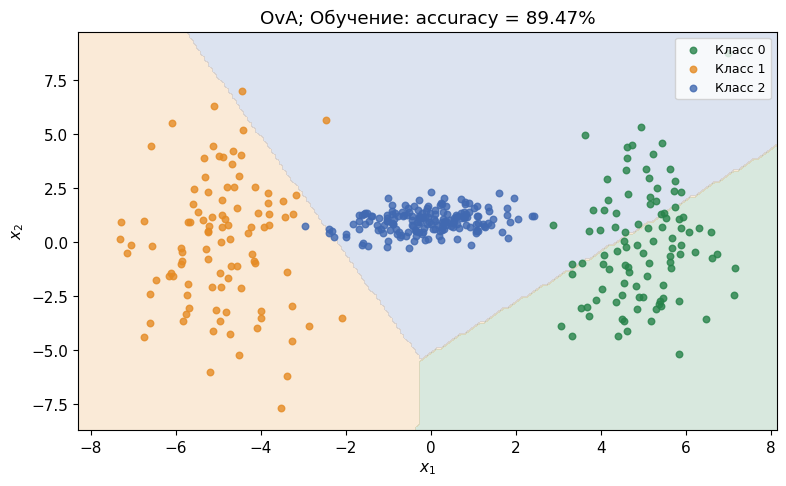

In [90]:
def plot_ensemble_bound(X, y, models, ensemble_pred, ax=None, colors=None,
                        dataset='Обучение', highlight=None, grid_data=None, zoom_limits=None):
    colors = class_colors if colors is None else colors
    xx, yy, grid = make_grid(X) if grid_data is None else grid_data
    region = ensemble_pred(grid, models).reshape(xx.shape)
    own_figure = ax is None
    if own_figure:
        fig, ax = plt.subplots(figsize=(8, 5))
    ax.contourf(xx, yy, region, levels=np.arange(len(colors) + 1) - .5,
                alpha=.18, cmap=ListedColormap(colors))
    for label, color in enumerate(colors):
        ax.scatter(*X[y == label].T, color=color, label=f'Класс {label}',
                   s=22 if len(y) < 1000 else 5, alpha=.8 if len(y) < 1000 else .22)
    if highlight is not None:
        ax.scatter(*X[highlight].T, facecolors='none', edgecolors='#222222',
                   s=60 if len(y) < 1000 else 15, linewidths=.8 if len(y) < 1000 else .3)
    strategy = 'OvA' if ensemble_pred is ova_ensemble_pred else 'AvA'
    accuracy = np.mean(ensemble_pred(X, models) == y)
    ax.set(title=f'{strategy}; {dataset}: accuracy = {accuracy:.2%}',
           xlabel='$x_1$', ylabel='$x_2$')
    ax.legend(fontsize=9, loc='upper right')
    if zoom_limits is not None:
        xmin, xmax, ymin, ymax = zoom_limits
        zoom_x, zoom_y = np.meshgrid(np.linspace(xmin, xmax, 100), np.linspace(ymin, ymax, 100))
        zoom_grid = np.c_[zoom_x.ravel(), zoom_y.ravel()]
        inset = ax.inset_axes([.61, .07, .36, .34])
        zoom_region = ensemble_pred(zoom_grid, models).reshape(zoom_x.shape)
        inset.contourf(zoom_x, zoom_y, zoom_region, levels=np.arange(len(colors) + 1) - .5,
                       alpha=.18, cmap=ListedColormap(colors))
        for label, color in enumerate(colors):
            inset.scatter(*X[y == label].T, color=color, s=15)
        if highlight is not None:
            inset.scatter(*X[highlight].T, facecolors='none', edgecolors='#222222',
                           s=45, linewidths=.7)
        inset.set(xlim=(xmin, xmax), ylim=(ymin, ymax), xticks=[], yticks=[])
        inset.set_title('Общая группа', fontsize=8)
    if own_figure:

        plt.tight_layout()
        plt.show()


plot_ensemble_bound(X, y, models_ova, ova_ensemble_pred)

<details>
<summary><b>Почему получилась такая граница? Достаточно ли нормировать оценки?</b></summary>

Средний кластер лежит между двумя боковыми. Одна прямая не может выделить полосу между ними: боковые облака доходят до высоты $x_2=1$, и для любой линейной оценки $g_2(x)=w_2^Tx+b_2$:
$$
g_2((0,1))=\tfrac12g_2((-5,1))+\tfrac12g_2((5,1)).
$$
Если обе боковые точки имеют отрицательную оценку, средняя тоже не может иметь положительную. Бинарной модели «класс 2 против остальных» приходится допускать ошибки. Попарная модель может отделять средний кластер от каждого бокового своей прямой.

Итоговый OvA, однако, выбирает **наибольшую оценку**, а не её знак:
$$
f(x)=\arg\max_k g_k(x),\qquad
R_k=\{x:\ g_k(x)\geq g_j(x)\ \text{для всех }j\}.
$$
Поэтому итоговая область среднего класса может лежать между двумя прямыми, хотя одна бинарная модель полосу выделить не может. Её края задаются равенствами двух максимальных оценок $g_k(x)=g_j(x)$, а не бинарными границами $g_k(x)=0$. Но модели обучались независимо на своих бинарных задачах: такое обучение не гарантирует удачного положения итоговых границ.

Нормировка
$$
\widetilde g_k(x)=\frac{g_k(x)}{\|w_k\|}
$$
даёт знаковое расстояние до соответствующей прямой. Она сохраняет бинарные границы, но меняет сравнение оценок разных моделей. Расстояния до разных прямых не являются вероятностями классов, поэтому такая нормировка не гарантирует улучшения. Сравним исходные и нормированные оценки на срезе $x_2=1$, проходящем через центр среднего кластера.

</details>


In [ ]:
controversial_ids = np.flatnonzero((y == 2) & (ova_ensemble_pred(X, models_ova) != y))[:5]
score_table = pd.DataFrame(
    np.column_stack([model.decision_function(X[controversial_ids]) for model in models_ova]),
    columns=['Оценка класса 0', 'Оценка класса 1', 'Оценка класса 2'],
    index=controversial_ids,
)
score_table['Истинный класс'] = y[controversial_ids]
score_table['Ответ OvA'] = ova_ensemble_pred(X[controversial_ids], models_ova)
score_table.round(3)

,Оценка класса 0,Оценка класса 1,Оценка класса 2,Истинный класс,Ответ OvA
194,-5.967,0.256,-0.450,2,1
327,-5.343,-0.340,-0.391,2,1


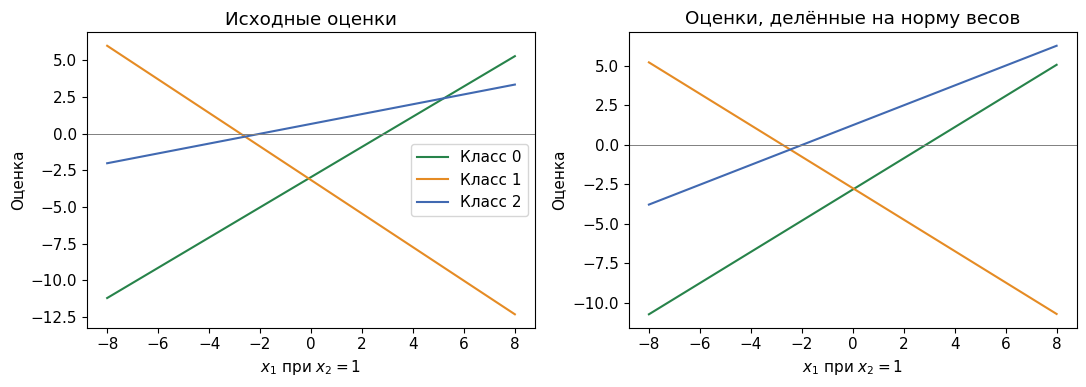

In [ ]:
x_line = np.linspace(-8, 8, 300)
points = np.column_stack([x_line, np.ones_like(x_line)])
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
for label, (model, color) in enumerate(zip(models_ova, class_colors)):
    score = model.decision_function(points)
    axes[0].plot(x_line, score, color=color, label=f'Класс {label}')
    axes[1].plot(x_line, score / np.linalg.norm(model.coef_), color=color)
for ax, title in zip(axes, ['Исходные оценки', 'Оценки, делённые на норму весов']):
    ax.set(xlabel='$x_1$ при $x_2=1$', ylabel='Оценка', title=title)
    ax.axhline(0, color='gray', linewidth=.7)
axes[0].legend()
plt.tight_layout()
plt.show()

### Все против всех (all versus all)

Обучим $C^2_K$ линейных классификаторов $a_{ij}(x)$, отделяющих класс $i$ от класса $j,\,\,\,$ $1\leq i<j\leq K$. В этом случае классификатор настраивается по подвыборке $X_{ij} \subset X$, содержащей только объекты классов $i$ или $j$:
$$
X_{ij} = \left\{(x_n, y_n) \in X \,\bigg|\, \mathbb{I}[y_n = i] = 1\, \text{или}\, \mathbb{I}[y_n = j] = 1\right\}.
$$
Чтобы классифицировать новый объект, подадим его на вход каждого из построенных бинарных классификаторов. Каждый из них возвращает одну из меток $i$ или $j$ и голосует за неё; в качестве ответа выберем тот класс, за который наберется больше всего голосов:
$$
a(x) = \arg\max_{k \in \{1, \ldots, K\}}\sum_{1\leq i<j\leq K}\mathbb{I}[a_{ij}(x) = k]
$$
При равенстве числа голосов нужна договорённость. В нашем коде `scipy.stats.mode` выбирает наименьшую метку среди модальных значений.


In [91]:
models_ava = []
for first, second in pairs:
    mask = (y == first) | (y == second)
    # y = [0, 0, 1, 2, 0, 2]
    #
    y_binary = np.where(y[mask] == first, 1, -1)
    model = SGDClassifier(**sgd_parameters).fit(X[mask], y_binary)
    models_ava.append(model)
models = models_ava

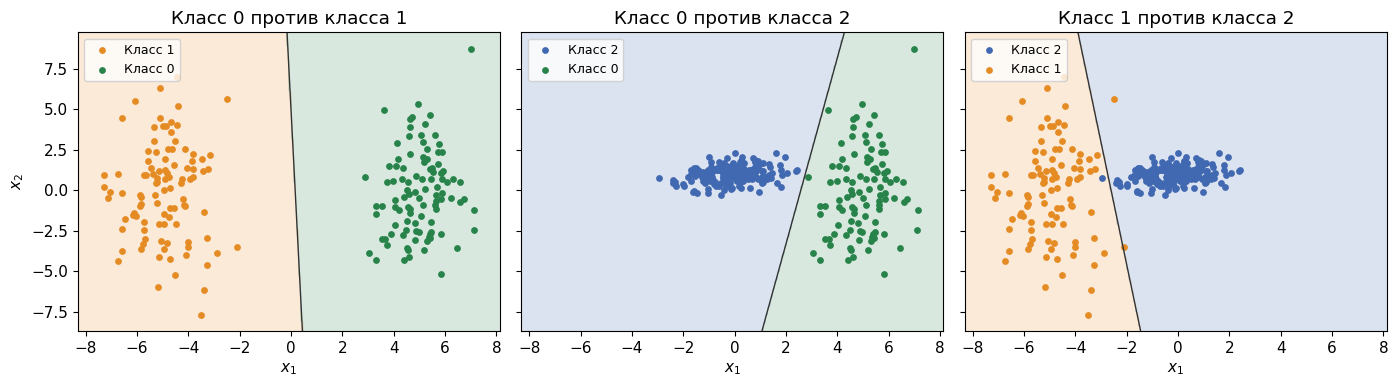

In [92]:
plot_binary_bound(X, y, models, mode='ava')

In [93]:
from scipy.stats import mode


def make_remapping(predictions, pair):
    return np.where(predictions == 1, pair[0], pair[1])


def ava_ensemble_pred(X, models, target_pairs=pairs):
    votes = np.column_stack([make_remapping(model.predict(X), pair)
                             for model, pair in zip(models, target_pairs)])
    return mode(votes, axis=1).mode.ravel()

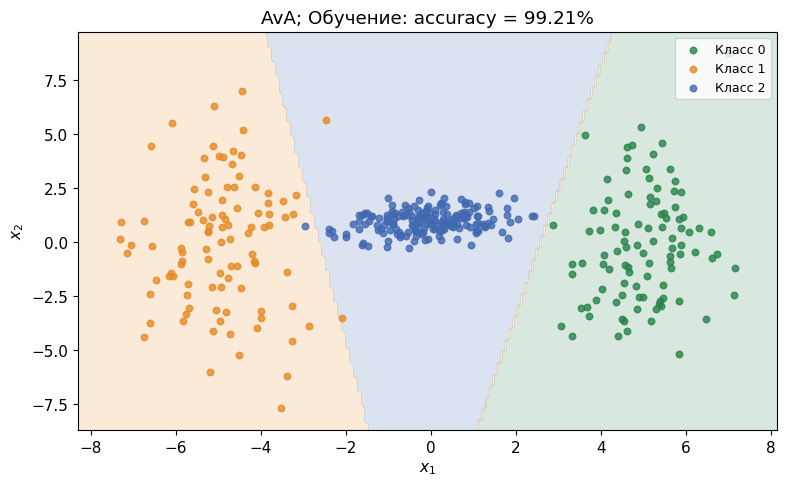

In [94]:
plot_ensemble_bound(X, y, models, ava_ensemble_pred)

### Набор данных с шумными сэмплами

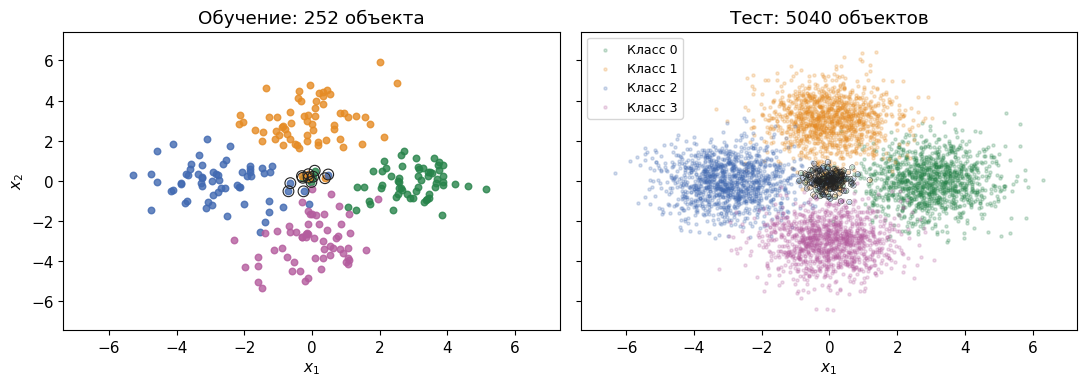

In [95]:
def create_noisy_data(seed, multiplier=1):
    rng = np.random.default_rng(seed)
    centers = np.array([[3., 0.], [0., 3.], [-3., 0.], [0., -3.]])
    main = np.vstack([rng.normal(center, 1., size=(60 * multiplier, 2)) for center in centers])
    noise = np.vstack([rng.normal([0., 0.], .35, size=(4 * multiplier, 2)) for _ in range(3)])
    X = np.vstack([main, noise])
    y = np.r_[np.repeat(np.arange(4), 60 * multiplier), np.repeat(np.arange(3), 4 * multiplier)]
    noise_mask = np.arange(len(y)) >= len(main)
    order = rng.permutation(len(y))
    return X[order], y[order], noise_mask[order]


noisy_X, noisy_y, noisy_mask = create_noisy_data(SEED)
noisy_test_X, noisy_test_y, noisy_test_mask = create_noisy_data(SEED + 100, multiplier=20)
noisy_colors = class_colors + ['#b45c9e']
noisy_grid = make_grid(np.vstack([noisy_X, noisy_test_X]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, sharey=True)
for ax, points, labels, mask, name in zip(
        axes, [noisy_X, noisy_test_X], [noisy_y, noisy_test_y], [noisy_mask, noisy_test_mask],
        ['Обучение: 252 объекта', 'Тест: 5040 объектов']):
    for label, color in enumerate(noisy_colors):
        ax.scatter(*points[labels == label].T, color=color, label=f'Класс {label}',
                   s=22 if len(labels) < 1000 else 5, alpha=.8 if len(labels) < 1000 else .22)
    ax.scatter(*points[mask].T, facecolors='none', edgecolors='#222222',
               s=60 if len(labels) < 1000 else 15, linewidths=.8 if len(labels) < 1000 else .3)
    ax.set(title=name, xlabel='$x_1$', xlim=(noisy_grid[0].min(), noisy_grid[0].max()),
           ylim=(noisy_grid[1].min(), noisy_grid[1].max()))
axes[0].set_ylabel('$x_2$')
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()


В случае 4-х классов OvA имеет 4 разделяющие модели, а AvA 6.

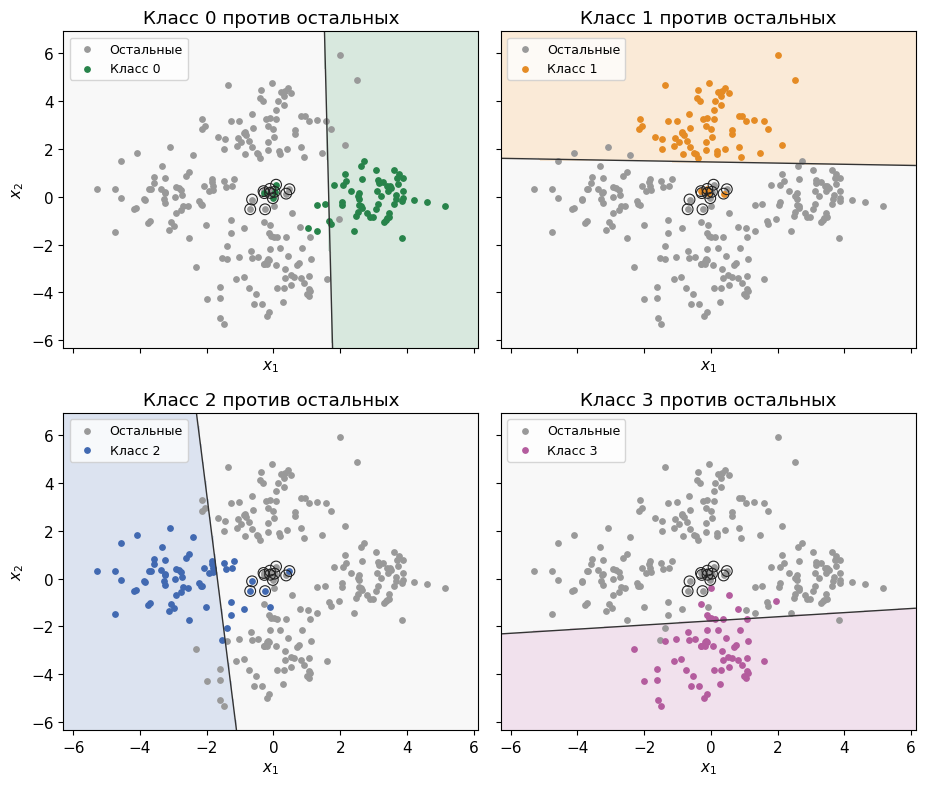

In [96]:
noisy_models_ova = [SGDClassifier(**sgd_parameters).fit(noisy_X, np.where(noisy_y == label, 1, -1))
                    for label in range(4)]
plot_binary_bound(noisy_X, noisy_y, noisy_models_ova, colors=noisy_colors, highlight=noisy_mask)

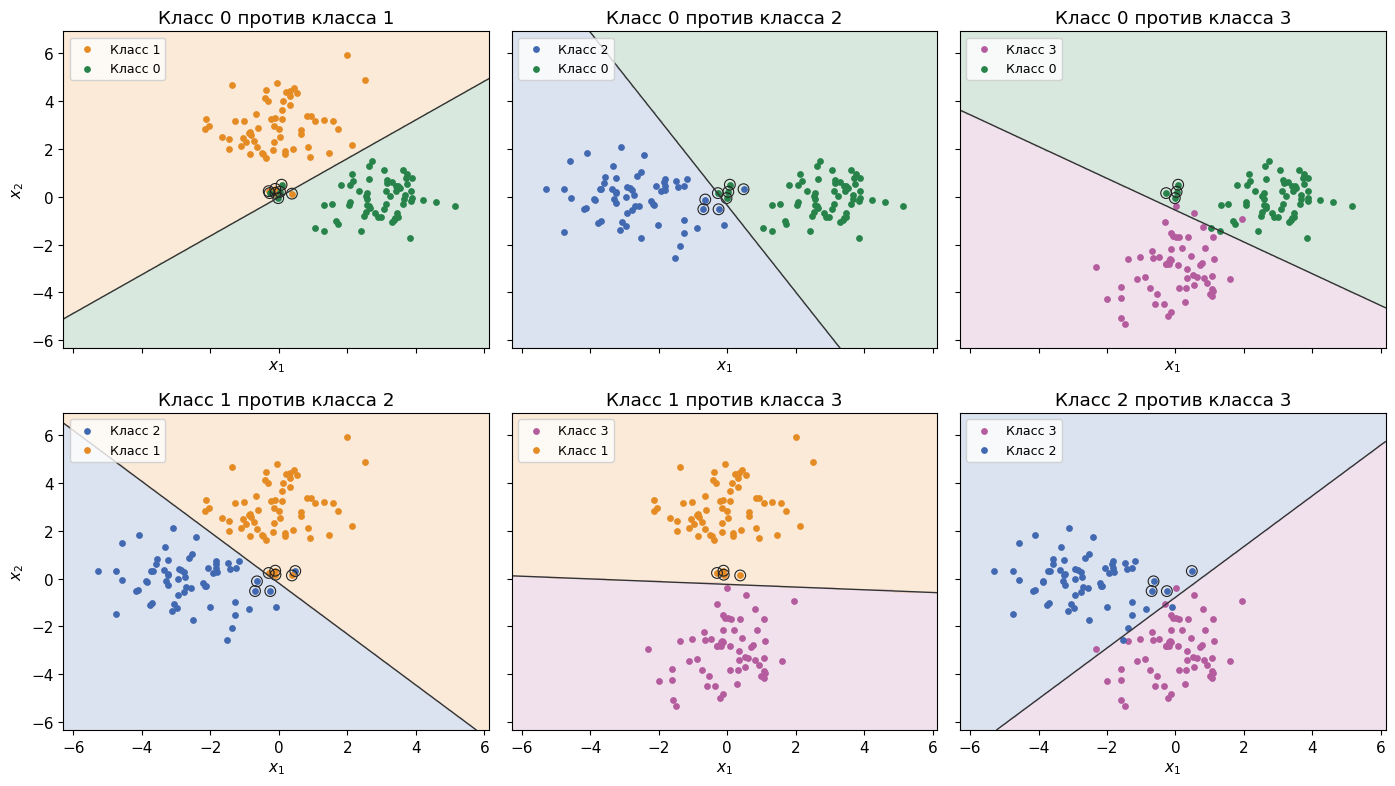

In [97]:
noisy_pairs = list(combinations(range(4), 2))
noisy_models_ava = []
for first, second in noisy_pairs:
    mask = (noisy_y == first) | (noisy_y == second)
    model = SGDClassifier(**sgd_parameters).fit(
        noisy_X[mask], np.where(noisy_y[mask] == first, 1, -1))
    noisy_models_ava.append(model)
plot_binary_bound(noisy_X, noisy_y, noisy_models_ava, mode='ava', target_pairs=noisy_pairs,
                  colors=noisy_colors, highlight=noisy_mask)

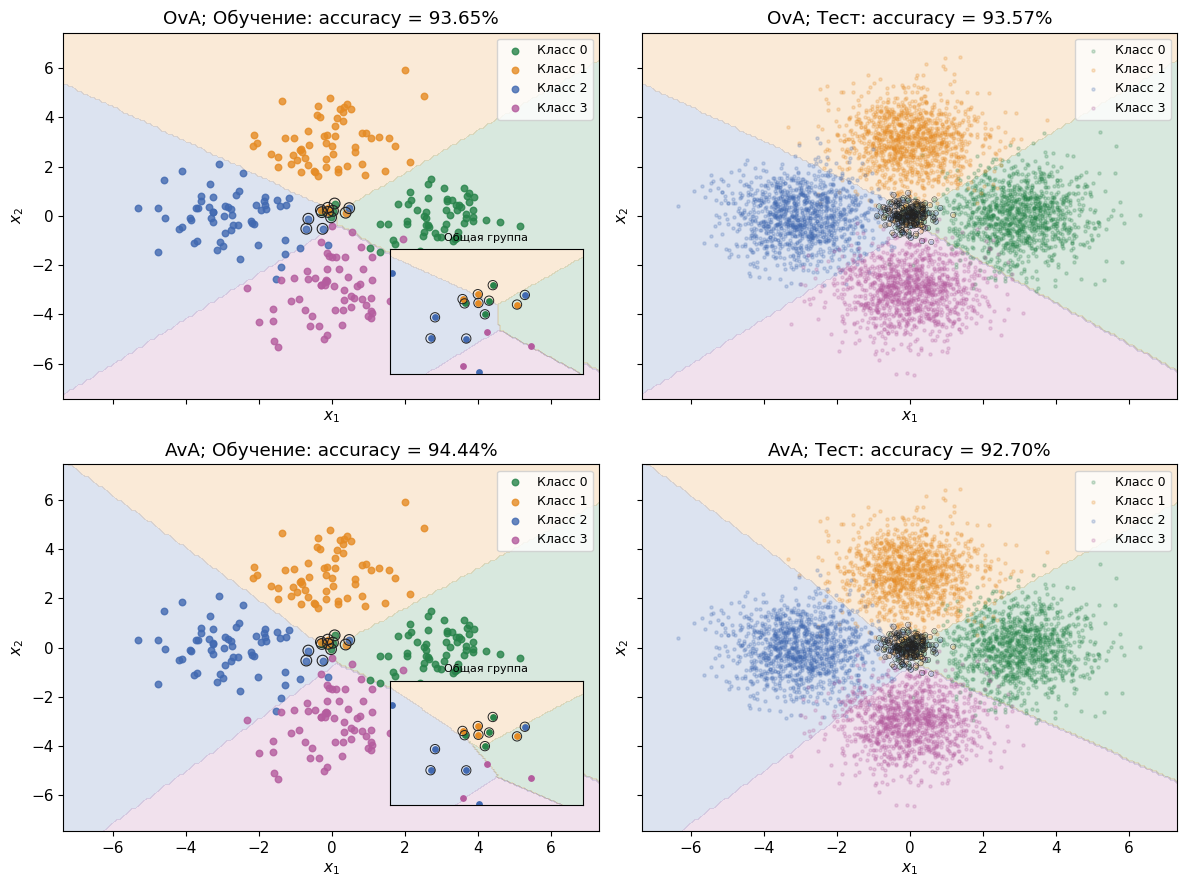

In [ ]:
def noisy_ava_prediction(points, models):
    return ava_ensemble_pred(points, models, noisy_pairs)


noisy_strategies = {'OvA': (noisy_models_ova, ova_ensemble_pred),
                    'AvA': (noisy_models_ava, noisy_ava_prediction)}
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for row, (name, models, prediction) in enumerate(
        (name, *values) for name, values in noisy_strategies.items()):
    for column, (points, labels, mask, dataset) in enumerate([
            (noisy_X, noisy_y, noisy_mask, 'Обучение'),
            (noisy_test_X, noisy_test_y, noisy_test_mask, 'Тест')]):
        plot_ensemble_bound(points, labels, models, prediction, ax=axes[row, column],
                            colors=noisy_colors, dataset=dataset, highlight=mask, grid_data=noisy_grid,
                            zoom_limits=(-1.2, 1.2, -1.2, 1.2) if column == 0 else None)
plt.tight_layout()
plt.show()

noise_results = []
for name, (models, prediction) in noisy_strategies.items():
    for points, labels, mask, dataset in [
            (noisy_X, noisy_y, noisy_mask, 'Обучение'),
            (noisy_test_X, noisy_test_y, noisy_test_mask, 'Тест')]:
        correct = prediction(points, models) == labels
        noise_results.append({'Стратегия': name, 'Выборка': dataset,
                              'Все объекты': correct.mean(),
                              'Основные кластеры': correct[~mask].mean(),
                              'Шумовая группа': correct[mask].mean()})
pd.DataFrame(noise_results).set_index(['Выборка', 'Стратегия']).sort_index().style.format('{:.2%}')

AvA угадал 7 из 12 обучающих объектов общей группы, OvA — 4 из 12. У линейного OvA область класса задаётся пересечением полуплоскостей $g_k(x)\geq g_j(x)$ и потому выпукла. AvA принимает решение голосованием отдельных пар: это другое построение областей, а каждая модель оценивается по меньшей выборке. В результате на истинной популяции такое смещение AvA на небольшом обучающем наборе приводит к лёгкому переобучению.

## Логистическая Регрессия

<details>
<summary><b>Напоминание: бинарная логистическая регрессия</b></summary>

Идея: давайте свяжем выход $z \in (-\infty, +\infty)$ линейной регрессии с вероятностью выбора положительного класса $p \in (0, 1)$. Для этого представим $z$ в виде **логита**
$$
\langle w, x_i \rangle = \log\left(\dfrac{p}{1-p}\right).
$$
Отсюда можно выразить искомую вероятность:
$$
p = \dfrac{1}{1 + e^{-\langle w, x_i \rangle}}.
$$
Функция в правой части называется **сигмоидой**
$$
\sigma(z) = \dfrac{1}{1 + e^{-z}}
$$
Для меток $y_i\in\{0,1\}$ минимизируем отрицательный логарифм правдоподобия распределения Бернулли:
$$
\mathcal{L}(w, X, y) = -\dfrac{1}{N}\sum_{i=1}^N \log p(y_i | x_i, w) = -\dfrac{1}{N}\sum_{i=1}^N (y_i\log(\sigma(\langle w, x_i \rangle)) + (1 - y_i)\log(\sigma(-\langle w, x_i \rangle)))
$$

</details>

<details>
<summary><b>Напоминание: многоклассовая логистическая регрессия</b></summary>

Бинарную логистическую регрессию можно напрямую обобщить на случай многих классов.
$$
z = \underbrace{X}_{n\times d}\underbrace{W}_{d\times K} + w_0
$$
Связывание вектора $z$ с вектором вероятностей $p$ происходит с помощью SoftMax оператора:
$$
SoftMax(z) = \begin{pmatrix}
\dfrac{\exp{(z_1)}}{\sum_{i=1}^K \exp{(z_i)}}, & \ldots & ,\dfrac{\exp{(z_K)}}{\sum_{i=1}^K \exp{(z_i)}}
\end{pmatrix}^\top
$$
В таком случае оптимизируемая функция потерь
$$
\mathcal{L}(W, X, y) = -\dfrac{1}{N}\sum_{i=1}^N \log p(y_i | x_i, W) = \dfrac{1}{N}\sum_{i=1}^N \left[\log\left(\sum_{j=1}^K \exp{(z_{ij})}\right)-z_{i,y_i}\right]
$$

</details>

#### **Почему использование SoftMax обобщает бинарную лог.-регрессию?**

SoftMax является обобщением сигмоидной функции. Рассмотрим функцию SoftMax для $z = \begin{pmatrix}z_1, & z_2\end{pmatrix}^\top$. Первая компонента вероятности
$$
\dfrac{\exp{(z_1)}}{\exp{(z_1)} + \exp{(z_2)}} = \dfrac{\exp{(z_1 - z_2)}}{1 + \exp{(z_1 - z_2)}} = \sigma(z_1 - z_2).
$$
Аналогично для второй компоненты
$$
\dfrac{\exp{(z_2)}}{\exp{(z_1)} + \exp{(z_2)}} = \sigma(z_2 - z_1)
$$
Обозначая $z := z_1 - z_2$ получаем, что SoftMax описывает 2 компоненты сигмоиды $\sigma(z)$ и $\sigma(-z)=1-\sigma(z)$ как и в бинарном случае.

#### Численная устойчивость: приём log-sum-exp

Поскольку $z_i \in (-\infty, +\infty)$, то мы можем столкнуться с численными неустойчивостями при прямом подсчёте SoftMax:

In [98]:
def softmax(z):
    return np.exp(z) / np.sum(np.exp(z))

z0 = np.array([-3, 0.4])
z1 = np.array([998, 1000])

print(f"Softmax for z0: {softmax(z0)}")
print(f"Softmax for z1: {softmax(z1)}")

Softmax for z0: [0.03229546 0.96770454]
Softmax for z1: [nan nan]


/tmp/ipykernel_438/2674662712.py:2: RuntimeWarning: overflow encountered in exp
  return np.exp(z) / np.sum(np.exp(z))
/tmp/ipykernel_438/2674662712.py:2: RuntimeWarning: invalid value encountered in divide
  return np.exp(z) / np.sum(np.exp(z))


Воспользуемся тем, что в оптимизируемом функционале стоит log-sum-exp и применим следующий "трюк":
$$
\log\left(\sum_{j=1}^K \exp{(z_i)}\right) = \log\left(\sum_{j=1}^K \exp{(z_i - c)}\exp{(c)}\right) = c + \log\left(\sum_{j=1}^K \exp{(z_i - c)}\right).
$$
Таким образом мы убрали экспоненциальную зависимость в линейную. В качестве $c$ логично выбрать $\max_{j}z_j$. Этого же эффекта можно достичь непосредственно при вычислении SoftMax'а

In [99]:
def SoftMax_Stabilized(z):
    c = np.max(z)
    return np.divide(np.exp(z-c), np.sum(np.exp(z-c)))

print(f"Stabilized SoftMax for z0: {SoftMax_Stabilized(z0)}")
print(f"Stabilized SoftMax for z1: {SoftMax_Stabilized(z1)}")

Stabilized SoftMax for z0: [0.03229546 0.96770454]
Stabilized SoftMax for z1: [0.11920292 0.88079708]


Таким образом, версия, где лоссу подаются сырые логиты вычислительно более стабильная, чем навешивание софт-макса в конец слоя (https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)

### Лог. Регрессия на MNIST

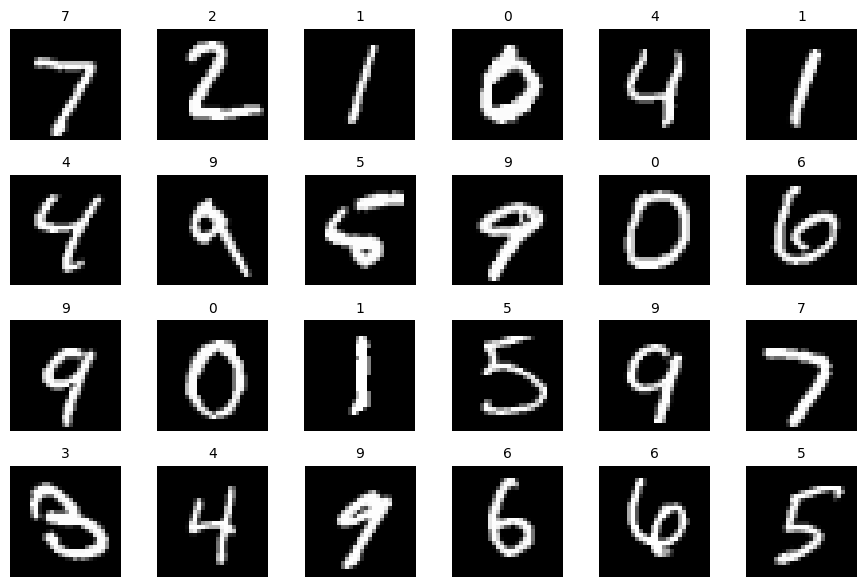

In [100]:
import gzip
from urllib.request import urlretrieve
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


def read_mnist(filename, offset, shape):
    path = Path('data/MNIST/raw') / filename
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f'https://ossci-datasets.s3.amazonaws.com/mnist/{filename}', path)
    with gzip.open(path, 'rb') as file:
        return np.frombuffer(file.read(), dtype=np.uint8, offset=offset).reshape(shape)


X_train = read_mnist('train-images-idx3-ubyte.gz', 16, (-1, 784)).astype(np.float32) / 255
X_test = read_mnist('t10k-images-idx3-ubyte.gz', 16, (-1, 784)).astype(np.float32) / 255
y_train = read_mnist('train-labels-idx1-ubyte.gz', 8, (-1,))
y_test = read_mnist('t10k-labels-idx1-ubyte.gz', 8, (-1,))

fig, axes = plt.subplots(4, 6, figsize=(9, 6))
for image, label, ax in zip(X_test[:24], y_test[:24], axes.flat):
    ax.imshow(image.reshape(28, 28), cmap='gray', vmin=0, vmax=1)
    ax.set_title(str(label), fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

In [101]:
from sklearn.linear_model import LogisticRegression

[Параметры LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)

* `C` задаёт обратную силу регуляризации: меньше `C` — сильнее штраф.
* `penalty='l2'` добавляет квадратичный штраф на веса. Для elastic net используется комбинация $\lambda[(1-\rho)\|w\|_2^2/2+\rho\|w\|_1]$.
* `solver` выбирает алгоритм оптимизации. `lbfgs` — метод с ограниченной памятью; `sag` и `saga` используют стохастические обновления с уменьшением дисперсии. Для них существенно масштабирование признаков.
* `max_iter` и `tol` задают условия остановки. Если достигнут лимит итераций, проверьте сходимость перед интерпретацией результатов.

In [102]:
clf = LogisticRegression(penalty='l2', solver='sag', tol=0.01,
                         max_iter=100, random_state=SEED)
clf.fit(X_train, y_train)
print(f'Accuracy на тесте: {clf.score(X_test, y_test):.4f}')
print('Число итераций:', clf.n_iter_)

Accuracy на тесте: 0.9259
Число итераций: [34]


## Макро и Микро усреднения

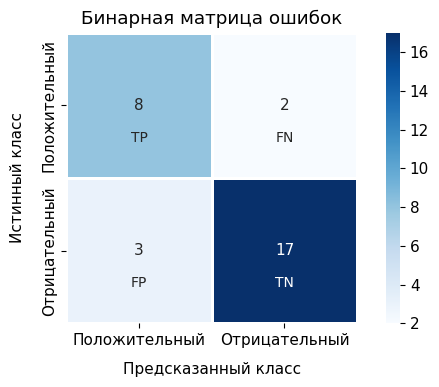

In [103]:
def draw_confusion(ax, matrix, title, labels=None, percent=False, cbar=True):
    sns.heatmap(matrix, annot=True, fmt='.0%' if percent else '.0f', cmap='Blues',
                cbar=cbar, square=True, linewidths=.8,
                xticklabels=labels or list('ABCD'),
                yticklabels=labels or list('ABCD'), ax=ax)
    ax.set(title=title, xlabel='Предсказанный класс', ylabel='Истинный класс')
    ax.xaxis.labelpad = 10
    ax.yaxis.labelpad = 12


fig, ax = plt.subplots(figsize=(6, 4))
draw_confusion(ax, np.array([[8, 2], [3, 17]]), 'Бинарная матрица ошибок',
               labels=['Положительный', 'Отрицательный'])
for (row, column), name in zip(np.ndindex(2, 2), ['TP', 'FN', 'FP', 'TN']):
    color = ax.texts[row * 2 + column].get_color()
    ax.text(column + .5, row + .75, name, ha='center', fontsize=10, color=color)
plt.tight_layout()
plt.show()


Формула точности (accuracy) в бинарном случае
$$
Acc = \dfrac{TP + TN}{TP + FN + FP + TN}
$$

##### **Что изменится в случае многих классов?**

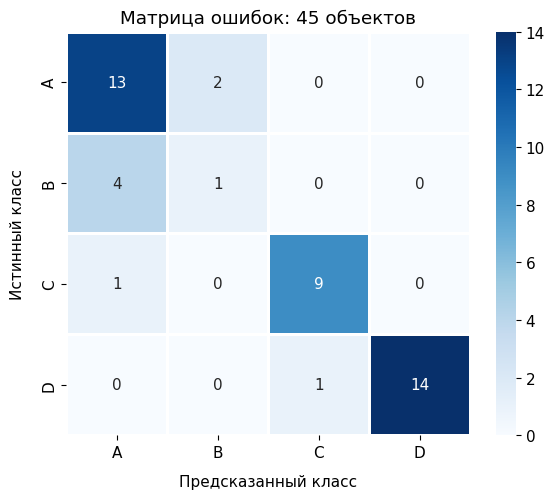

In [ ]:
example_matrix = np.array([[13, 2, 0, 0], [4, 1, 0, 0],
                           [1, 0, 9, 0], [0, 0, 1, 14]])
fig, ax = plt.subplots(figsize=(6, 5))
draw_confusion(ax, example_matrix, 'Матрица ошибок: 45 объектов')
plt.tight_layout()
plt.show()

Ничего:)

$$
Acc = \dfrac{TP_1 + TP_2 + \ldots + TP_K}{\sum_{i=1}^K TP_i + \sum_{i\neq j}^K E_{ij}}
$$

#### Несбалансированные выборки

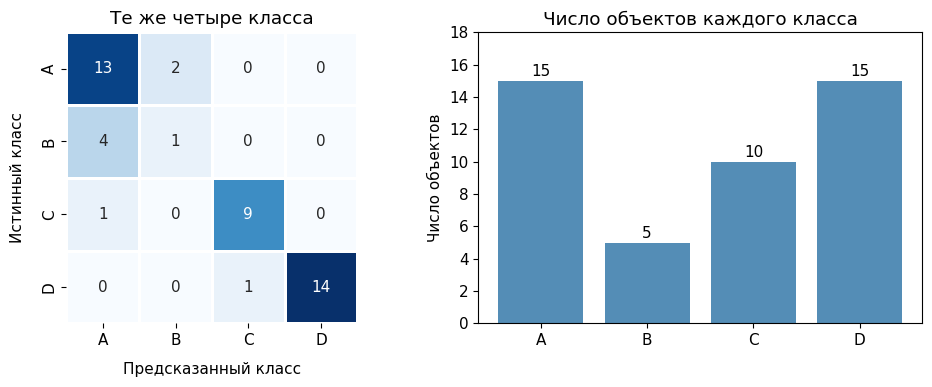

In [104]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
draw_confusion(axes[0], example_matrix, 'Те же четыре класса', cbar=False)
counts = example_matrix.sum(axis=1)
axes[1].bar(list('ABCD'), counts, color='#548db6')
for label, count in zip(list('ABCD'), counts):
    axes[1].text(label, count + .3, str(count), ha='center')
axes[1].set(title='Число объектов каждого класса', ylabel='Число объектов', ylim=(0, 18))
plt.tight_layout()
plt.show()

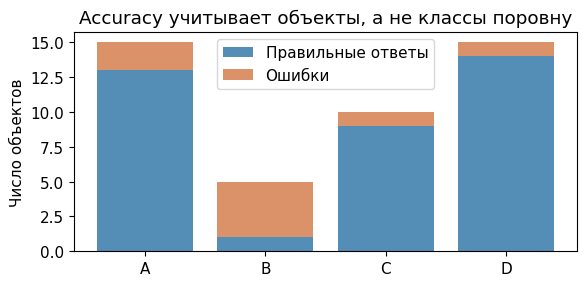

In [105]:
fig, ax = plt.subplots(figsize=(6, 3))
correct = np.diag(example_matrix)
ax.bar(list('ABCD'), correct, label='Правильные ответы', color='#548db6')
ax.bar(list('ABCD'), counts - correct, bottom=correct,
       label='Ошибки', color='#dc9268')
ax.set(ylabel='Число объектов', title='Accuracy учитывает объекты, а не классы поровну')
ax.legend()
plt.tight_layout()
plt.show()

Для класса $k$ считаем его положительным, а все остальные классы — отрицательными:
$$
Precision_k = \frac{TP_k}{TP_k+FP_k},\qquad
Recall_k = \frac{TP_k}{TP_k+FN_k},\qquad
F1_k = \frac{2Precision_kRecall_k}{Precision_k+Recall_k}.
$$
Precision отвечает на вопрос «сколько из предсказанных объектов класса $k$ действительно относятся к нему?», recall — «какую долю объектов класса $k$ нашли?».

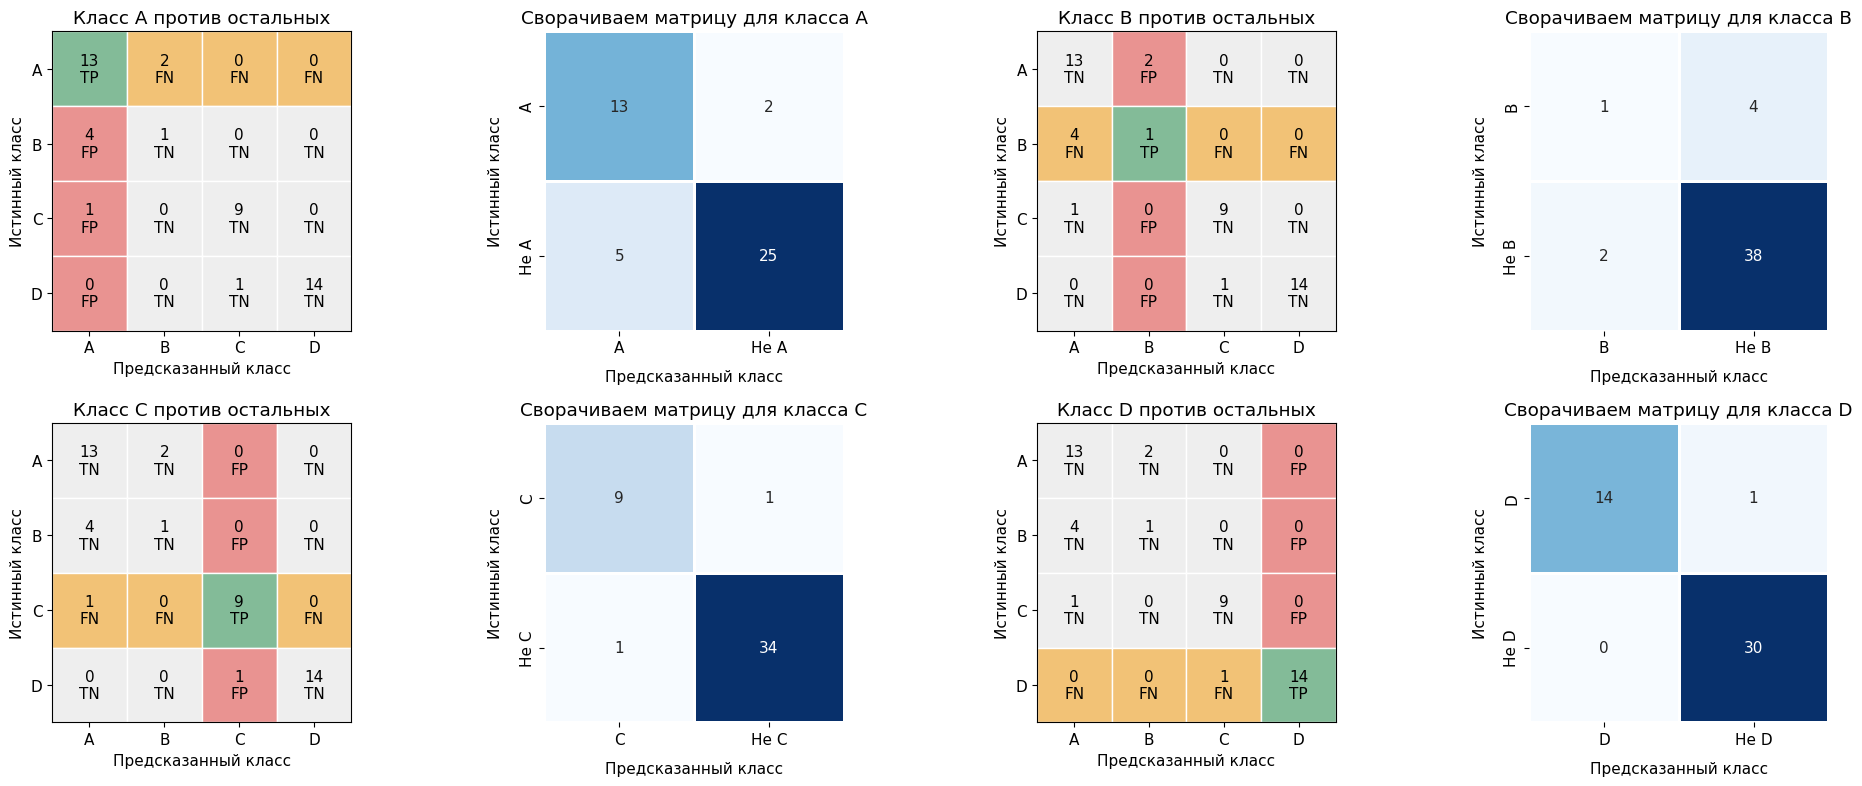

In [106]:
from matplotlib.patches import Rectangle

category_colors = {
    'TP': '#83bb98',
    'FN': '#f2c276',
    'FP': '#e99391',
    'TN': '#eeeeee'
}

fig, axes = plt.subplots(2, 4, figsize=(20, 8))

for class_index, class_label in enumerate('ABCD'):
    row = class_index // 2
    col_start = (class_index % 2) * 2

    cell_names = np.full(example_matrix.shape, 'TN', dtype=object)
    cell_names[class_index, :] = 'FN'
    cell_names[:, class_index] = 'FP'
    cell_names[class_index, class_index] = 'TP'

    # Левая картинка в паре: 4x4 матрица
    ax_left = axes[row, col_start]
    for (r, c), value in np.ndenumerate(example_matrix):
        name = cell_names[r, c]
        ax_left.add_patch(Rectangle(
            (c, r), 1, 1,
            facecolor=category_colors[name],
            edgecolor='white'
        ))
        ax_left.text(c + 0.5, r + 0.5, f'{value}\n{name}',
                     ha='center', va='center')

    ax_left.set(
        xlim=(0, 4), ylim=(4, 0), aspect='equal',
        xticks=np.arange(4) + 0.5,
        yticks=np.arange(4) + 0.5,
        xticklabels=list('ABCD'),
        yticklabels=list('ABCD'),
        xlabel='Предсказанный класс',
        ylabel='Истинный класс',
        title=f'Класс {class_label} против остальных'
    )

    # Правая картинка в паре: бинарная свёртка
    class_binary_matrix = np.array([
        [example_matrix[cell_names == 'TP'].sum(),
         example_matrix[cell_names == 'FN'].sum()],
        [example_matrix[cell_names == 'FP'].sum(),
         example_matrix[cell_names == 'TN'].sum()]
    ])

    ax_right = axes[row, col_start + 1]
    draw_confusion(
        ax_right,
        class_binary_matrix,
        f'Сворачиваем матрицу для класса {class_label}',
        labels=[class_label, f'Не {class_label}'],
        cbar=False
    )

plt.tight_layout()
plt.show()

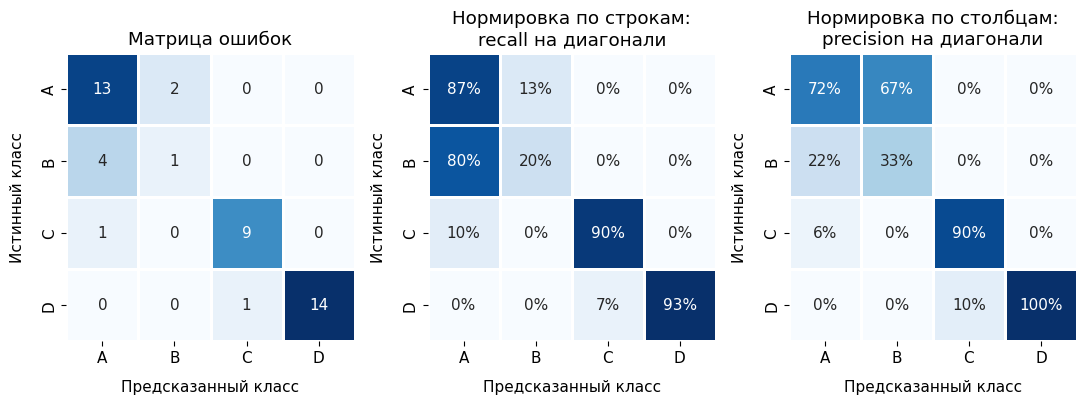

In [107]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
draw_confusion(axes[0], example_matrix, 'Матрица ошибок', cbar=False)
draw_confusion(axes[1], example_matrix / example_matrix.sum(axis=1, keepdims=True),
               'Нормировка по строкам:\nrecall на диагонали', percent=True, cbar=False)
draw_confusion(axes[2], example_matrix / example_matrix.sum(axis=0, keepdims=True),
               'Нормировка по столбцам:\nprecision на диагонали', percent=True, cbar=False)
plt.tight_layout()
plt.show()

### Макроусреднение

Сначала считаем метрику для каждого класса, затем берём среднее с одинаковыми весами:
$$
Precision_{macro}=\frac1K\sum_k Precision_k,\qquad
Recall_{macro}=\frac1K\sum_k Recall_k,\qquad
F1_{macro}=\frac1K\sum_k F1_k.
$$
Каждый класс влияет одинаково, даже если в нём мало объектов. Macro-F1 — среднее готовых $F1_k$, а не F1, вычисленный из macro-precision и macro-recall.


In [108]:
Image(url='src/metrics_05.webp', width=1000)

In [109]:
true_positive = np.diag(example_matrix)
precision = true_positive / example_matrix.sum(axis=0)
recall = true_positive / example_matrix.sum(axis=1)
f1 = 2 * precision * recall / (precision + recall)
class_metrics = pd.DataFrame({
    'Precision': precision, 'Recall': recall, 'F1': f1,
    'Число объектов': example_matrix.sum(axis=1)
}, index=list('ABCD'))
metric_values = class_metrics[['Precision', 'Recall', 'F1']]
macro_values = np.vstack([metric_values.to_numpy(), metric_values.mean().to_numpy()])
display(metric_values.mean().to_frame('Макроусреднение').T.round(4))

,Precision,Recall,F1
Макроусреднение,0.7389,0.725,0.7258


### Усреднение с весами классов (weighted)

Можно усреднить те же метрики с весами $n_k/N$, где $n_k$ — число истинных объектов класса $k$:
$$
Precision_{weighted}=\sum_k\frac{n_k}{N}Precision_k,\qquad
Recall_{weighted}=\sum_k\frac{n_k}{N}Recall_k,\qquad
F1_{weighted}=\sum_k\frac{n_k}{N}F1_k.
$$


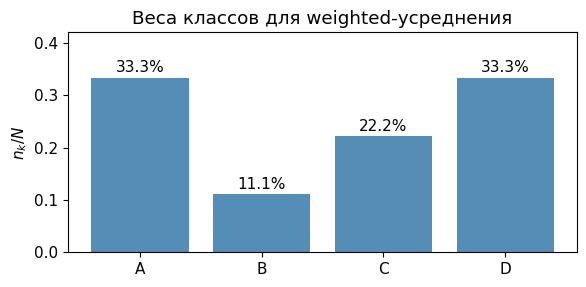

In [110]:
weights = counts / counts.sum()
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(list('ABCD'), weights, color='#548db6')
for label, weight in zip(list('ABCD'), weights):
    ax.text(label, weight + .01, f'{weight:.1%}', ha='center')
ax.set(title='Веса классов для weighted-усреднения', ylabel='$n_k / N$', ylim=(0, .42))
plt.tight_layout()
plt.show()

In [ ]:
averaging_results = pd.DataFrame([
    metric_values.mean(),
    metric_values.mul(weights, axis=0).sum(),
], index=['Макроусреднение', 'Усреднение с весами'])
averaging_results.round(4)

,Precision,Recall,F1
Макроусреднение,0.7389,0.7250,0.7258
Усреднение с весами,0.8111,0.8222,0.8122


У класса B пять объектов из 45, поэтому его вес в weighted — $5/45$, а в macro — $1/4$. Его низкие precision и recall слабее влияют на weighted-результат.


### Микроусреднение

Сначала складываем счётчики всех классов, затем вычисляем метрику:
$$
Precision_{micro}=\frac{\sum_k TP_k}{\sum_k TP_k+\sum_k FP_k},\qquad
Recall_{micro}=\frac{\sum_k TP_k}{\sum_k TP_k+\sum_k FN_k},
$$
$$
F1_{micro}=\frac{2\sum_k TP_k}{2\sum_k TP_k+\sum_k FP_k+\sum_k FN_k}.
$$
Здесь не усредняются готовые precision, recall и F1. На рисунке последняя строка — сумма счётчиков, а не среднее.


In [ ]:
Image(url='src/metrics_06.webp', width=1000)

In [111]:
pooled_counts = pd.DataFrame({
    'TP': np.diag(example_matrix),
    'FP': example_matrix.sum(axis=0) - np.diag(example_matrix),
    'FN': example_matrix.sum(axis=1) - np.diag(example_matrix),
}, index=list('ABCD'))
pooled_counts.loc['Сумма'] = pooled_counts.sum()
pooled_counts

tp, fp, fn = pooled_counts.loc['Сумма', ['TP', 'FP', 'FN']]
micro_precision = tp / (tp + fp)
micro_recall = tp / (tp + fn)
micro_f1 = 2 * tp / (2 * tp + fp + fn)
averaging_results.loc['Микроусреднение'] = [micro_precision, micro_recall, micro_f1]

display(averaging_results.round(4))
print(f'Accuracy = {np.trace(example_matrix) / example_matrix.sum():.4f}')

,Precision,Recall,F1
Макроусреднение,0.7389,0.7250,0.7258
Усреднение с весами,0.8111,0.8222,0.8122
Микроусреднение,0.8222,0.8222,0.8222


Accuracy = 0.8222


<details>
<summary><b>Почему micro-Precision == micro-Recall == Accuracy?</b></summary>

Узнаете в дз:)
</details>

### Метрики Лог. Регрессии на MNIST

In [112]:
from sklearn.metrics import classification_report

report = classification_report(y_test, clf.predict(X_test), digits=4)
print(report)

              precision    recall  f1-score   support

           0     0.9532    0.9776    0.9652       980
           1     0.9602    0.9780    0.9690      1135
           2     0.9309    0.9012    0.9158      1032
           3     0.9039    0.9129    0.9084      1010
           4     0.9387    0.9348    0.9367       982
           5     0.8963    0.8722    0.8841       892
           6     0.9403    0.9530    0.9466       958
           7     0.9331    0.9222    0.9276      1028
           8     0.8833    0.8778    0.8805       974
           9     0.9097    0.9187    0.9142      1009

    accuracy                         0.9259     10000
   macro avg     0.9250    0.9248    0.9248     10000
weighted avg     0.9257    0.9259    0.9257     10000



Можно заметить, что classification_report не отображает micro-метрики, т.к. accuracy уже их репортит.

### Specificity для несбалансированных метрик

Рассмотрим сценарий с детекцией патологии. Здоровых людей (слава богу) больше, чем больных. Как распространённость патологии в популяции будет отражаться на рассмотренных метриках?

$Recall=\frac{TP}{TP+FN}$ — какую долю случаев патологии нашли. Для медицинских задач её иногда называют *Sensitivity*.

$Specificity=\frac{TN}{TN+FP}$ — какую долю людей без этой патологии верно отнесли к отрицательному классу.

$Precision = \frac{TP}{TP + FP}$ какую долю случаев с предсказанной патологией модель определила верно. В медицинских задачах её также называют Positive Predictive Value (PPV). В реальности эта метрика отражает нагрузку на врачей в системе здравоохранения.

Пусть Sensitivity равна 90%, Specificity — 95%. Сравним две группы по 10 000 человек с разной долей патологии.

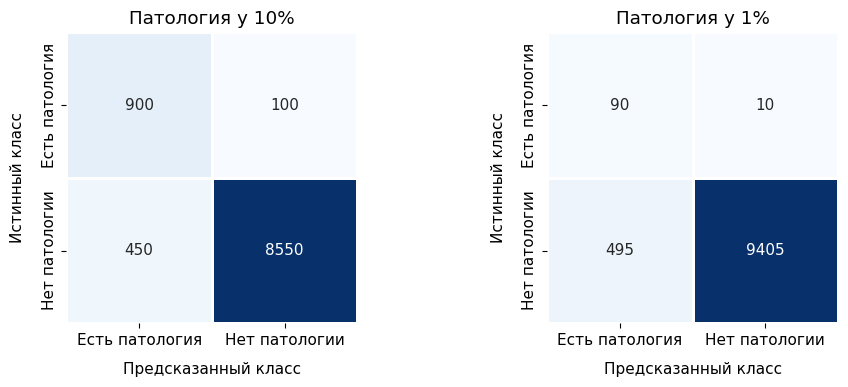

,Precision,Sensitivity,Specificity,F1,G-mean
Группа,,,,,
Патология у 10%,0.6667,0.9,0.95,0.7660,0.9247
Патология у 1%,0.1538,0.9,0.95,0.2628,0.9247


In [113]:
medical_matrices = {
    'Патология у 10%': np.array([[900, 100], [450, 8550]]),
    'Патология у 1%': np.array([[90, 10], [495, 9405]]),
}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
medical_rows = []
for ax, (name, matrix) in zip(axes, medical_matrices.items()):
    draw_confusion(ax, matrix, name, labels=['Есть патология', 'Нет патологии'], cbar=False)
    tp, fn, fp, tn = matrix.ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    medical_rows.append({'Группа': name, 'Precision': tp / (tp + fp),
                         'Sensitivity': sensitivity, 'Specificity': specificity,
                         'F1': 2 * tp / (2 * tp + fp + fn),
                         'G-mean': np.sqrt(sensitivity * specificity)})
plt.tight_layout()
plt.show()
pd.DataFrame(medical_rows).set_index('Группа').round(4)

Специфичность лучше отражает именно предсказательную силу модели. Аналогом гармонического среднего (F1-score) в медицине является геометрическое среднее: $G\text{-}mean=\sqrt{Sensitivity\cdot Specificity}$

Но при разной распространённости патологии $\pi$ метрика $G\text{-}mean$ не отражает нагрузку на врача при выдаче положительного диагноза. Для Precision справедливо следующее соотношение

$$
Precision = \frac{\pi\cdot Sensitivity}{\pi\cdot Sensitivity+(1-\pi)(1-Specificity)}.
$$

Для регулирования соотношения между Чувствительностью и Специфичностью обученной модели $\sigma(r(x))$ к полученным значениям вероятности для всего набора подбирается порог по заданным критериям. Например, максимизирующем $G\text{-}mean$

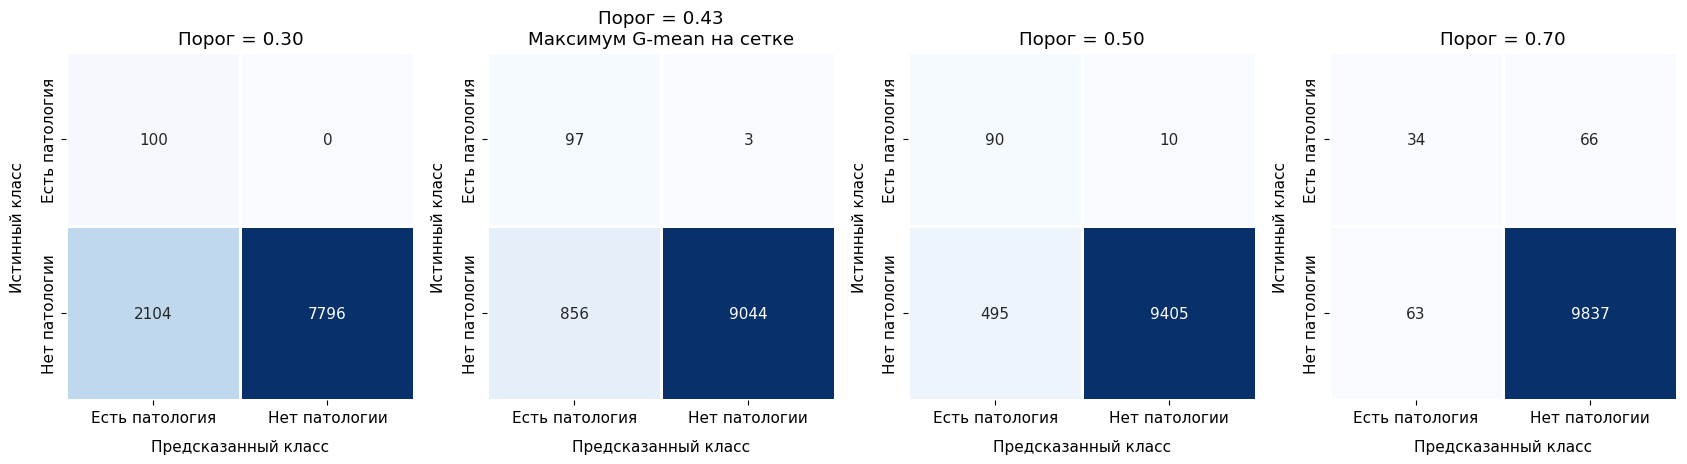

,Sensitivity,Specificity,G-mean,Precision,Положительных ответов
Порог,,,,,
0.30,1.00,0.7875,0.8874,0.0454,2204
0.43,0.97,0.9135,0.9413,0.1018,953
0.50,0.90,0.9500,0.9247,0.1538,585
0.70,0.34,0.9936,0.5812,0.3505,97


In [114]:
from scipy.stats import norm
from scipy.special import expit
from sklearn.metrics import confusion_matrix

rng = np.random.default_rng(42)

# Normal quantiles ensure exactly 90% sensitivity and 95% specificity at 0.5.
positive_quantiles = (np.arange(100) + .5) / 100
negative_quantiles = (np.arange(9900) + .5) / 9900
positive_scores = .5 * (norm.ppf(positive_quantiles) + norm.ppf(.9))
negative_scores = norm.ppf(negative_quantiles) + norm.ppf(.05)

y_valid = np.r_[np.ones(100, dtype=int), np.zeros(9900, dtype=int)]
probabilities_valid = expit(np.r_[positive_scores, negative_scores])
order = rng.permutation(len(y_valid))
y_valid, probabilities_valid = y_valid[order], probabilities_valid[order]


def evaluate_threshold(threshold):
    predictions = (probabilities_valid >= threshold).astype(int)
    matrix = confusion_matrix(y_valid, predictions, labels=[1, 0])
    tp, fn, fp, tn = matrix.ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    metrics = {
        'Порог': threshold,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'G-mean': np.sqrt(sensitivity * specificity),
        'Precision': tp / (tp + fp) if tp + fp else np.nan,
        'Положительных ответов': tp + fp,
    }
    return matrix, metrics


threshold_table = pd.DataFrame([
    evaluate_threshold(threshold)[1]
    for threshold in np.linspace(.01, .99, 99)
])
best_threshold = threshold_table.loc[
    threshold_table['G-mean'].idxmax(), 'Порог'
]

selected_thresholds = [.3, best_threshold, .5, .7]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
selected_rows = []

for ax, threshold in zip(axes, selected_thresholds):
    matrix, metrics = evaluate_threshold(threshold)
    title = f'Порог = {threshold:.2f}'
    if threshold == best_threshold:
        title += '\nМаксимум G-mean на сетке'
    draw_confusion(
        ax, matrix, title,
        labels=['Есть патология', 'Нет патологии'],
        cbar=False,
    )
    selected_rows.append(metrics)

plt.tight_layout()
plt.show()
display(pd.DataFrame(selected_rows).set_index('Порог').round(4))

В примере виден стандартный компромисс в выборе порога: $t=0.43$ в сравнении с $t=0.5$ на 7% повышает чувствительность, но вместе с этим регистрирует 856 (против 495) ложных тревог, что существенно увеличивает нагрузку на перепроверку врачами.


## Многометная (Multilabel) Классификация

<img src = 'src/multilabel_banner.png' width = 2000>

### Логистическая регрессия для многометной задачи

Мы обобщали бинарную логистическую регрессию на случай многоклассовой классификации. Давайте аналогично поступим для многометной:

$$
z = \underbrace{X}_{n\times d}\underbrace{W}_{d\times K} + w_0
$$
Логиты $z$ не ограничены симплексом ни в многоклассовой, ни в многометной задаче. Здесь каждая вероятность $p_j=\sigma(z_j)$ описывает наличие соответствующей метки; сумма этих вероятностей не обязана равняться единице. Определим соответствующий оператор:
$$
\sigma^K(z) = \begin{pmatrix}
\sigma(z_1), & \ldots & ,\sigma(z_K)
\end{pmatrix}^\top
$$
При условной независимости меток в данной модели правдоподобие всей выборки
$$
p(Y | X, W) = \prod_{i=1}^N\prod_{j=1}^K p(y_{ij} | x_i, W).
$$
И оптимизируемый функционал
$$
\mathcal{L}(W, X, y) = -\dfrac{1}{NK}\sum_{i=1}^N\sum_{j=1}^K \log p(y_{ij} | x_i, W) = -\dfrac{1}{NK}\sum_{i=1}^N\sum_{j=1}^K \left[y_{ij}\log p_{ij}+(1-y_{ij})\log(1-p_{ij})\right].
$$
Мы получили знакомую бинарную кросс-энтропию, усреднённую по каждому из классов.

### Метрики многометной классификации

Пусть $Y_i$ — множество истинных меток, $\hat Y_i$ — предсказанных.

* **Subset accuracy** — доля объектов, у которых весь набор меток совпал: $\frac1N\sum_i\mathbb{I}[Y_i=\hat Y_i]$. Одна неверная метка делает ответ на объект целиком неправильным.
* **Hamming loss** — доля ошибок среди всех $NK$ бинарных ответов: $\frac1{NK}\sum_{i,j}\mathbb{I}[y_{ij}\ne\hat y_{ij}]$. Чем меньше, тем лучше. Если метки редки, постоянный ответ «нет меток» может иметь небольшую потерю.
* **Micro-F1** — сначала суммируем TP, FP, FN по всем меткам и объектам, затем считаем F1. Частые метки дают больший вклад.
* **Macro-F1** — считаем F1 отдельно для каждой метки и усредняем с одинаковыми весами.
* **Samples-F1** — считаем $\frac{2|Y_i\cap\hat Y_i|}{|Y_i|+|\hat Y_i|}$ для каждого объекта и усредняем. Каждый объект получает одинаковый вес, даже если число его меток отличается.

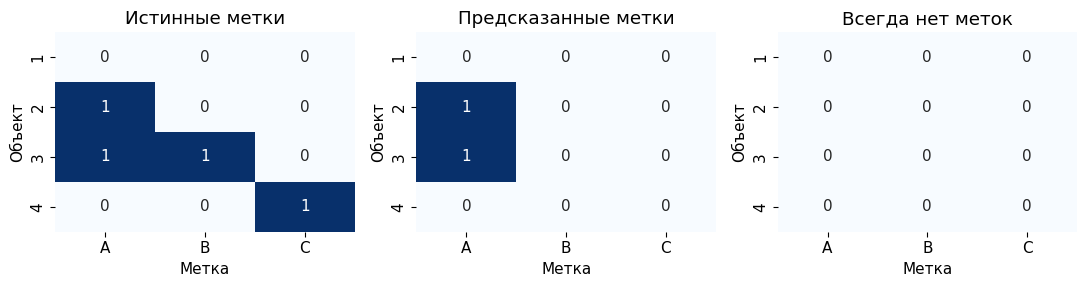

,Subset accuracy,Hamming loss,Micro-F1,Macro-F1,Samples-F1
Модель,0.50,0.1667,0.6667,0.3333,0.4167
Всегда нет меток,0.25,0.3333,0.0000,0.0000,0.0000


In [ ]:
from sklearn.metrics import accuracy_score, hamming_loss, f1_score

multilabel_true = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 0, 1]])
multilabel_pred = np.array([[0, 0, 0], [1, 0, 0], [1, 0, 0], [0, 0, 0]])
multilabel_empty = np.zeros_like(multilabel_true)

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, matrix, title in zip(axes, [multilabel_true, multilabel_pred, multilabel_empty],
                             ['Истинные метки', 'Предсказанные метки', 'Всегда нет меток']):
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=list('ABC'), yticklabels=range(1, 5), ax=ax, vmin=0, vmax=1)
    ax.set(title=title, xlabel='Метка', ylabel='Объект')
plt.tight_layout()
plt.show()


def multilabel_metrics(y_true, y_pred):
    return {'Subset accuracy': accuracy_score(y_true, y_pred),
            'Hamming loss': hamming_loss(y_true, y_pred),
            'Micro-F1': f1_score(y_true, y_pred, average='micro', zero_division=0),
            'Macro-F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
            'Samples-F1': f1_score(y_true, y_pred, average='samples', zero_division=0)}


pd.DataFrame({
    'Модель': multilabel_metrics(multilabel_true, multilabel_pred),
    'Всегда нет меток': multilabel_metrics(multilabel_true, multilabel_empty),
}).T.round(4)

Фактически, модель корректно предсказывает только метку А.Поэтому macro-усреднение даёт 1/3. Микро-усреднение вносит существенный вклад за счёт негативных истинных меток B, C у объектов 1,2.  

## Набор данных [PTB-XL](https://physionet.org/content/ptb-xl/1.0.3/)

In [ ]:
from pathlib import Path
from zipfile import ZipFile

import gdown
import pandas as pd

files = {
    'ptbxl_features.zip': '1BggNYgJEU1AlL3eDnCJZUFX5HBnRb9Fg',
    '00001_hr.hea': '1tkZP35O8fV7eX8E2UoPhcXvFaKGM5Imd',
    '00001_hr.dat': '1P90YQqR1oJM3Jy2ILezzfvVHqS2uv3Fe',
}

for filename, file_id in files.items():
    if not Path(filename).exists():
        gdown.download(id=file_id, output=filename, quiet=False)

archive_path = Path('ptbxl_features.zip')
with ZipFile(archive_path) as archive:
    df = pd.read_csv(archive.open('ptbxl_features/map_file.csv'))

print(f'Число записей: {len(df):,}')

Downloading...
From: https://drive.google.com/uc?id=1tkZP35O8fV7eX8E2UoPhcXvFaKGM5Imd
To: /content/00001_hr.hea
100%|██████████| 605/605 [00:00<00:00, 1.45MB/s]
Downloading...
From: https://drive.google.com/uc?id=1P90YQqR1oJM3Jy2ILezzfvVHqS2uv3Fe
To: /content/00001_hr.dat
100%|██████████| 120k/120k [00:00<00:00, 13.4MB/s]


Число записей: 21,372


In [ ]:
df.columns

Index(['file_name', 'ecg_shape', 'frequency', 'ecg_duration', 'mkv',
       'patient_id', 'doctor_id', 'device_name', 'report', 'scp_codes',
       'report_date', 'original_filename', 'nurse', 'site', 'validated_by',
       'second_opinion', 'initial_autogenerated_report', 'validated_by_human',
       'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems',
       'pacemaker', 'strat_fold', 'extra_beats', 'heart_axis',
       'infarction_stadium1', 'infarction_stadium2', 'age', 'target'],
      dtype='object')

In [ ]:
df['scp_codes']

,scp_codes
0,"['NORM', 'LVOLT', 'SR']"
1,"['NORM', 'SBRAD']"
2,"['NORM', 'SR']"
3,"['NORM', 'SR']"
4,"['NORM', 'SR']"
...,...
21367,"['NORM', 'ABQRS', 'SR']"
21368,"['CRBBB', 'LAFB', '1AVB', 'ABQRS', 'SVARR']"
21369,"['NORM', 'ABQRS', 'VCLVH', 'SR']"
21370,"['IRBBB', 'LAFB', 'SR']"


In [ ]:
import importlib.util

if importlib.util.find_spec('wfdb') is None:
    !pip -q install wfdb==4.3.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 5.4 MB/s eta 0:00:00


[Документация](https://wfdb-python.readthedocs.io/en/latest/index.html) wfdb

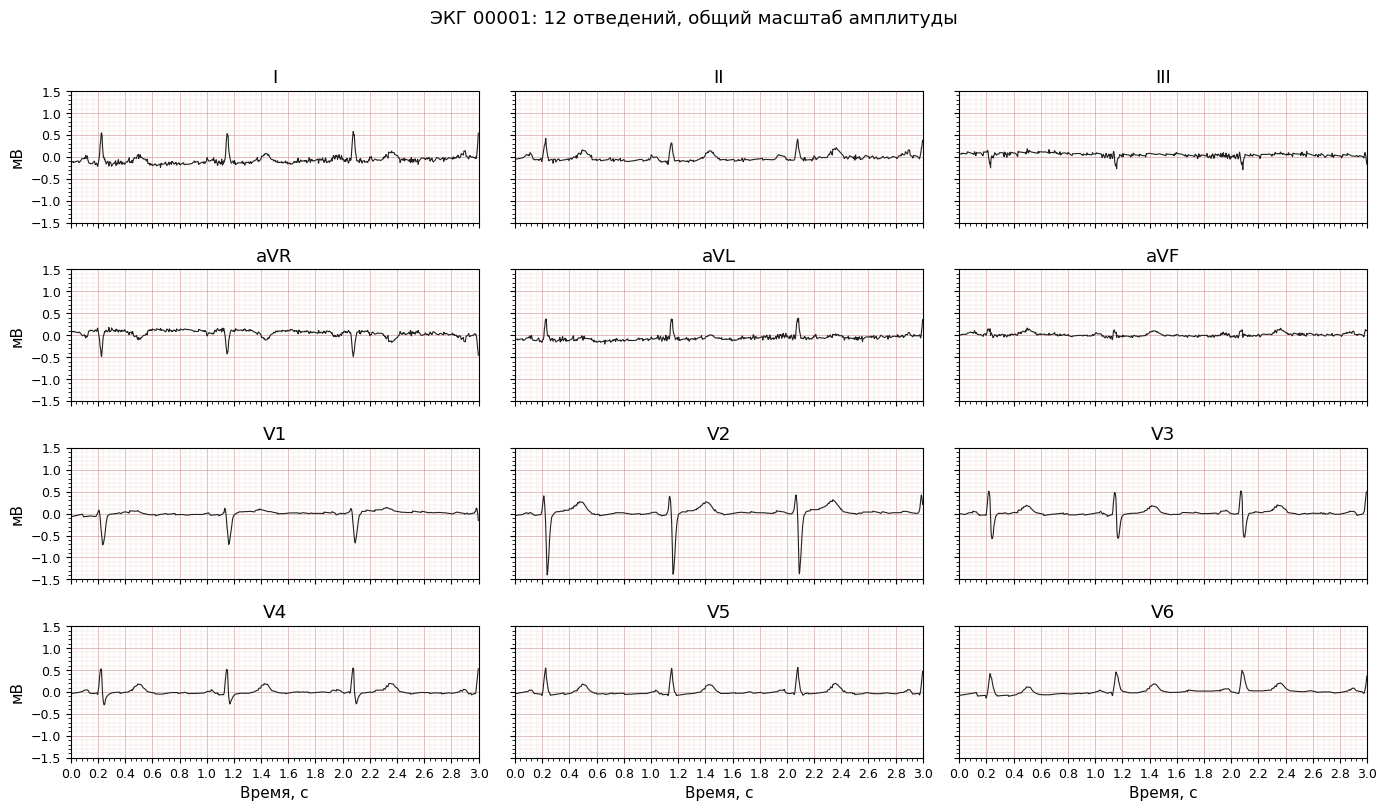

In [ ]:
import wfdb
from matplotlib.ticker import MultipleLocator

record = wfdb.rdrecord('00001_hr')
signal = record.p_signal
fs = record.fs
seconds = 3
segment = signal[:int(seconds * fs)]
time = np.arange(len(segment)) / fs
limit = np.ceil(np.max(np.abs(segment)) * 2) / 2
lead_names = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF',
              'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

fig, axes = plt.subplots(4, 3, figsize=(14, 8), sharex=True, sharey=True)
for lead, ax in enumerate(axes.flat):
    ax.plot(time, segment[:, lead], color='#222222', linewidth=.8)
    ax.set(title=lead_names[lead], xlim=(0, seconds), ylim=(-limit, limit))
    ax.xaxis.set_major_locator(MultipleLocator(.2))
    ax.xaxis.set_minor_locator(MultipleLocator(.04))
    ax.yaxis.set_major_locator(MultipleLocator(.5))
    ax.yaxis.set_minor_locator(MultipleLocator(.1))
    ax.grid(which='major', color='#d7a5a5', linewidth=.5)
    ax.grid(which='minor', color='#efdddd', linewidth=.3)
    ax.tick_params(labelsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel('мВ')
for ax in axes[-1]:
    ax.set_xlabel('Время, с')
fig.suptitle('ЭКГ 00001: 12 отведений, общий масштаб амплитуды', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
signal.shape

(5000, 12)

Выберем три метки:

1. AFIB — фибрилляция предсердий.
2. PVC — желудочковые экстрасистолы.
3. CRBBB — полная блокада правой ножки пучка Гиса.

Они могут встречаться одновременно. Отсутствие всех трёх меток не означает, что ЭКГ или пациент здоровы: другие состояния здесь не предсказываем.

In [ ]:
target_codes = ['AFIB', 'PVC', 'CRBBB']
with ZipFile(archive_path) as archive:
    X = np.stack([np.load(io.BytesIO(archive.read(f'ptbxl_features/{filename}')))['arr_0']
                  for filename in df['file_name']])
code_sets = [set(ast.literal_eval(value)) for value in df['scp_codes']]
y = np.array([[int(code in codes) for code in target_codes] for codes in code_sets])

print('Размер массива признаков:', X.shape)
print('Размер массива меток:', y.shape)

Размер массива признаков: (21372, 512)
Размер массива меток: (21372, 3)


### Разбиение по пациентам; одинаковые веса классов

Используем рекомендованные группы PTB-XL: `strat_fold` 1–8 для обучения, 9 для калибровки, 10 для теста. ЭКГ одного пациента не попадают в разные части. На всех следующих сравнениях тест один и тот же.

In [ ]:
from sklearn.multioutput import MultiOutputClassifier, ClassifierChain
from sklearn.pipeline import make_pipeline

train_mask = df['strat_fold'].to_numpy() <= 8
calibration_mask = df['strat_fold'].to_numpy() == 9
test_mask = df['strat_fold'].to_numpy() == 10
X_train, y_train = X[train_mask], y[train_mask]
X_calibration, y_calibration = X[calibration_mask], y[calibration_mask]
X_test, y_test = X[test_mask], y[test_mask]

split_masks = {'Обучение': train_mask, 'Калибровка': calibration_mask, 'Тест': test_mask}
split_summary = pd.DataFrame({name: {'Записей': int(mask.sum()),
                                    'Пациентов': df.loc[mask, 'patient_id'].nunique(),
                                    **dict(zip(target_codes, y[mask].sum(axis=0)))}
                              for name, mask in split_masks.items()}).T
display(split_summary)
patient_sets = {name: set(df.loc[mask, 'patient_id']) for name, mask in split_masks.items()}
print('Пересечения пациентов:',
      {f'{first} / {second}': len(patient_sets[first] & patient_sets[second])
       for first, second in [('Обучение', 'Калибровка'), ('Обучение', 'Тест'), ('Калибровка', 'Тест')]})


def make_base_model(class_weight=None):
    return make_pipeline(StandardScaler(), LogisticRegression(
        solver='lbfgs', max_iter=500, random_state=SEED, class_weight=class_weight))


base_pipeline = make_base_model()
ptb_models = {}
ptb_predictions = {}

,Записей,Пациентов,AFIB,PVC,CRBBB
Обучение,17089,14734,1169,893,423
Калибровка,2132,1899,138,107,51
Тест,2151,1861,143,109,53


Пересечения пациентов: {'Обучение / Калибровка': 0, 'Обучение / Тест': 0, 'Калибровка / Тест': 0}


#### MultiOutputClassifier

Это описанная многометная логистическая регрессия: для каждой метки независимо обучается свой бинарный классификатор $p_{ij}=\sigma(\langle w_j,x_i\rangle+w_{0j})$.

In [ ]:
independent_model = MultiOutputClassifier(base_pipeline).fit(X_train, y_train)
ptb_models['Независимые метки'] = independent_model
ptb_predictions['Независимые метки'] = independent_model.predict(X_test)
print(classification_report(y_test, ptb_predictions['Независимые метки'],
                            target_names=target_codes, digits=3, zero_division=0))

              precision    recall  f1-score   support

        AFIB      0.850     0.832     0.841       143
         PVC      0.750     0.771     0.760       109
       CRBBB      0.850     0.642     0.731        53

   micro avg      0.812     0.777     0.794       305
   macro avg      0.817     0.748     0.777       305
weighted avg      0.814     0.777     0.793       305
 samples avg      0.103     0.099     0.099       305



#### ClassifierChain

В цепочке метки предсказываются последовательно: AFIB → PVC → CRBBB. Каждая модель получает исходные признаки и предыдущие метки, чтобы учитывать зависимости между ними.

Для $j$-й метки обучаем логистическую регрессию:
$$
p_{ij}=P(y_{ij}=1\mid x_i,y_{i1},\ldots,y_{i,j-1})
=\sigma\!\left(\langle w_j,x_i\rangle+w_{0j}
+\sum_{\ell<j}v_{j\ell}y_{i\ell}\right).
$$
Здесь $w_j$ — коэффициенты при исходных признаках, $v_{j\ell}$ — при предыдущих метках. Все коэффициенты обучаются вместе внутри каждой регрессии; модели обучаются отдельно.

Такое построение соответствует разложению совместной вероятности:
$$
p(y_i\mid x_i)=\prod_{j=1}^K
p(y_{ij}\mid x_i,y_{i1},\ldots,y_{i,j-1}).
$$

При обучении с `cv=None` предыдущие метки известны и используются их истинные значения. При предсказании вместо них подставляем уже полученные ответы $\hat y_{i\ell}$ в ту же формулу:
$$
\hat y_{ij}=\mathbb I[\hat p_{ij}\geq 0.5].
$$
Для AFIB дополнительных меток нет; PVC использует ответ для AFIB, CRBBB — ответы для AFIB и PVC. Поэтому ошибки могут передаваться дальше, а порядок влияет на результат. Последовательный выбор ответов не гарантирует максимума совместной вероятности.

In [ ]:
chain_model = ClassifierChain(base_pipeline, order=[0, 1, 2], random_state=SEED).fit(X_train, y_train)
ptb_models['Цепочка'] = chain_model
ptb_predictions['Цепочка'] = chain_model.predict(X_test)
print(classification_report(y_test, ptb_predictions['Цепочка'],
                            target_names=target_codes, digits=3, zero_division=0))

              precision    recall  f1-score   support

        AFIB      0.856     0.832     0.844       143
         PVC      0.771     0.771     0.771       109
       CRBBB      0.860     0.698     0.771        53

   micro avg      0.825     0.787     0.805       305
   macro avg      0.829     0.767     0.795       305
weighted avg      0.826     0.787     0.805       305
 samples avg      0.103     0.100     0.100       305



### Взвешанное усреденение классов

При редких метках большинство примеров отрицательные. Если пропуск положительного случая особенно нежелателен, можно увеличить его вклад в функцию потерь. Для каждой бинарной задачи `class_weight='balanced'` задаёт веса
$$
\alpha_1=\frac{N}{2N_1},\qquad \alpha_0=\frac{N}{2N_0},
$$
где $N_1$ и $N_0$ — числа положительных и отрицательных объектов в обучении. Суммарный вес каждого класса становится одинаковым.

Для BCE в PyTorch существует атрибут pos_weight: https://docs.pytorch.org/docs/2.14/generated/torch.nn.BCEWithLogitsLoss.html

In [ ]:
base_pipeline = make_base_model(class_weight='balanced')

#### MultiOutputClassifier

In [ ]:
balanced_model = MultiOutputClassifier(base_pipeline).fit(X_train, y_train)
ptb_models['Независимые метки, balanced'] = balanced_model
ptb_predictions['Независимые метки, balanced'] = balanced_model.predict(X_test)
print(classification_report(y_test, ptb_predictions['Независимые метки, balanced'],
                            target_names=target_codes, digits=3, zero_division=0))

              precision    recall  f1-score   support

        AFIB      0.627     0.916     0.744       143
         PVC      0.678     0.945     0.789       109
       CRBBB      0.681     0.925     0.784        53

   micro avg      0.654     0.928     0.767       305
   macro avg      0.662     0.929     0.773       305
weighted avg      0.654     0.928     0.767       305
 samples avg      0.111     0.116     0.112       305



#### ClassifierChain

In [ ]:
balanced_chain = ClassifierChain(base_pipeline, order=[0, 1, 2], random_state=SEED).fit(X_train, y_train)
ptb_models['Цепочка, balanced'] = balanced_chain
ptb_predictions['Цепочка, balanced'] = balanced_chain.predict(X_test)
print(classification_report(y_test, ptb_predictions['Цепочка, balanced'],
                            target_names=target_codes, digits=3, zero_division=0))

              precision    recall  f1-score   support

        AFIB      0.629     0.923     0.748       143
         PVC      0.673     0.945     0.786       109
       CRBBB      0.681     0.925     0.784        53

   micro avg      0.653     0.931     0.768       305
   macro avg      0.661     0.931     0.773       305
weighted avg      0.654     0.931     0.768       305
 samples avg      0.110     0.116     0.112       305



#### Сравнение

In [ ]:
binary_rows = []
for name, predictions in ptb_predictions.items():
    for index, code in enumerate(target_codes):
        tn, fp, fn, tp = confusion_matrix(
            y_test[:, index], predictions[:, index], labels=[0, 1]
        ).ravel()
        recall = tp / (tp + fn)
        specificity = tn / (tn + fp)
        binary_rows.append({
            'Метка': code, 'Модель': name,
            'TP': tp, 'FN': fn, 'FP': fp, 'TN': tn,
            'Precision': tp / (tp + fp) if tp + fp else 0.,
            'Recall': recall,
            'Specificity': specificity,
            'G-mean': np.sqrt(recall * specificity),
            'F1': 2 * tp / (2 * tp + fp + fn),
        })

binary_results = (
    pd.DataFrame(binary_rows)
    .set_index(['Метка', 'Модель'])
    .sort_index(level=0, sort_remaining=False)
)
binary_results[
    ['FN', 'FP', 'Precision', 'Recall', 'Specificity', 'G-mean', 'F1']
].round(4)

FN  FP  Precision  Recall  Specificity  \
Метка Модель                                                                
AFIB  Независимые метки            24  21     0.8500  0.8322       0.9895   
      Цепочка                      24  20     0.8561  0.8322       0.9900   
      Независимые метки, balanced  12  78     0.6268  0.9161       0.9612   
      Цепочка, balanced            11  78     0.6286  0.9231       0.9612   
CRBBB Независимые метки            19   6     0.8500  0.6415       0.9971   
      Цепочка                      16   6     0.8605  0.6981       0.9971   
      Независимые метки, balanced   4  23     0.6806  0.9245       0.9890   
      Цепочка, balanced             4  23     0.6806  0.9245       0.9890   
PVC   Независимые метки            25  28     0.7500  0.7706       0.9863   
      Цепочка                      25  25     0.7706  0.7706       0.9878   
      Независимые метки, balanced   6  49     0.6776  0.9450       0.9760   
      Цепочка, balanced             6  50     0.6732  0.9450       0.9755   

                                   G-mean      F1  
Метка Модель                                       
AFIB  Независимые метки            0.9074  0.8410  
      Цепочка                      0.9077  0.8440  
      Независимые метки, balanced  0.9383  0.7443  
      Цепочка, balanced            0.9419  0.7479  
CRBBB Независимые метки            0.7998  0.7312  
      Цепочка                      0.8343  0.7708  
      Независимые метки, balanced  0.9562  0.7840  
      Цепочка, balanced            0.9562  0.7840  
PVC   Независимые метки            0.8718  0.7602  
      Цепочка                      0.8725  0.7706  
      Независимые метки, balanced  0.9604  0.7893  
      Цепочка, balanced            0.9601  0.7863

Как и предполагалось, balanced-варианты повышают значение чувствительности, но компенсируется это снижением Precision

In [ ]:
def multilabel_gmean(y_true, y_pred):
    def calculate(axis):
        tp = (y_true * y_pred).sum(axis=axis)
        tn = ((1 - y_true) * (1 - y_pred)).sum(axis=axis)
        positives = y_true.sum(axis=axis)
        negatives = (1 - y_true).sum(axis=axis)
        denominator = positives * negatives

        product = np.divide(
            tp * tn, denominator,
            out=np.full_like(denominator, np.nan, dtype=float),
            where=denominator > 0,
        )
        return np.sqrt(product)

    return {
        'Micro-G-mean': float(calculate(None)),
        'Macro-G-mean': calculate(0).mean(),
        'Samples-G-mean': np.nanmean(calculate(1)),
    }


ptb_metric_table = pd.DataFrame({
    name: {
        **multilabel_metrics(y_test, predictions),
        **multilabel_gmean(y_test, predictions),
    }
    for name, predictions in {
        **ptb_predictions
    }.items()
}).T

ptb_metric_table.round(4)

,Subset accuracy,Hamming loss,Micro-F1,Macro-F1,Samples-F1,Micro-G-mean,Macro-G-mean,Samples-G-mean
Независимые метки,0.9461,0.0191,0.7940,0.7775,0.0994,0.8776,0.8597,0.8064
Цепочка,0.9479,0.0180,0.8054,0.7951,0.1000,0.8834,0.8715,0.8102
"Независимые метки, balanced",0.9270,0.0267,0.7669,0.7725,0.1120,0.9514,0.9516,0.9024
"Цепочка, balanced",0.9275,0.0267,0.7676,0.7727,0.1117,0.9530,0.9528,0.8987


Усреднённые F1 и G-mean демонстрируют тот же компромисс.

## Калибровка модели

### Почему логрегрессия может давать хорошие вероятности?

Рассмотрим одну метку $y\in\{0,1\}$, например AFIB. Обозначим истинную вероятность $p(x)=P(y=1\mid x)$. Е Для логистической регрессии предсказание имеет вид $\sigma(r(x))=\sigma(\langle w,x\rangle+w_0)$. При фиксированном $x$ её средняя логарифмическая потеря равна
$$
\ell(q;p)=-p\log q-(1-p)\log(1-q),\qquad
\frac{\partial \ell}{\partial q}=\frac{q-p}{q(1-q)}.
$$
Минимум по предсказываемому числу $q$ достигается при $q=p$. Таким образом, log-loss направляет обучение обычной логрегрессии на оценку исходных вероятностей.

### Что меняют веса классов?

Со сбалансированными весами минимизируется другая потеря:
$$
\ell_\alpha(q;p)=-\alpha_1p\log q-\alpha_0(1-p)\log(1-q).
$$
Её минимум и соответствующий логит:
$$
q^*(x)=\frac{\alpha_1p(x)}{\alpha_1p(x)+\alpha_0(1-p(x))},\qquad
\operatorname{logit}q^*(x)=\operatorname{logit}p(x)+\log\frac{\alpha_1}{\alpha_0}.
$$

При редком положительном классе $\alpha_1>\alpha_0$, поэтому $q^*>p$: выход завышен относительно исходной доли положительных объектов. Порог $q^*\geq0.5$ соответствует $p\geq\alpha_0/(\alpha_0+\alpha_1)$ — более низкому порогу по исходной вероятности. Этим объясняется рост recall в предыдущем сравнении.

### Проверим калибровку AFIB

Модель калибрована, если
$$
P(y=1\mid\hat p(X)=q)=q.
$$
На конечной выборке сгруппируем близкие вероятности в интервалы $B_m$. Точка калибровочной кривой —
$$
\left(\overline p_m,\overline y_m\right)=
\left(\frac1{|B_m|}\sum_{i\in B_m}\hat p_i,
      \frac1{|B_m|}\sum_{i\in B_m}y_i\right).
$$
Среднюю предсказанную вероятность сравниваем с наблюдаемой долей AFIB. Хорошая калибровка даёт точки около диагонали; точки ниже неё означают завышенную вероятность.

In [ ]:
unweighted_probabilities = np.column_stack([probabilities[:, 1]
                                           for probabilities in independent_model.predict_proba(X_test)])
balanced_probabilities = np.column_stack([probabilities[:, 1]
                                         for probabilities in balanced_model.predict_proba(X_test)])

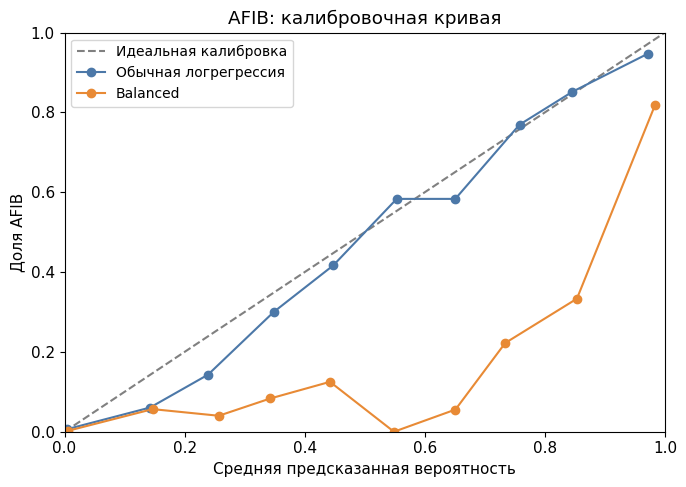

In [ ]:
def reliability_points(y_true, probabilities, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    groups = np.minimum(np.searchsorted(edges, probabilities, side='right') - 1, bins - 1)
    summary = pd.DataFrame({'group': groups, 'probability': probabilities, 'target': y_true})
    return summary.groupby('group').agg(probability=('probability', 'mean'),
                                       frequency=('target', 'mean'))


def plot_reliability(variants):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.plot([0, 1], [0, 1], '--', color='gray', label='Идеальная калибровка')
    for (name, probabilities), color in zip(variants.items(), ['#4c78a8', '#e88a35', '#4b9a66']):
        points = reliability_points(y_test[:, 0], probabilities[:, 0])
        ax.plot(points['probability'], points['frequency'], 'o-', label=name, color=color)
    ax.set(xlabel='Средняя предсказанная вероятность', ylabel='Доля AFIB',
           title='AFIB: калибровочная кривая', xlim=(0, 1), ylim=(0, 1))
    ax.legend(fontsize=10)
    plt.tight_layout()
    plt.show()


plot_reliability({'Обычная логрегрессия': unweighted_probabilities,
                  'Balanced': balanced_probabilities})

### Исправим вероятности balanced-модели

Обычная логрегрессия остаётся ориентиром. Калибруем только уже обученную balanced-модель: её линейную оценку $s(x)$ преобразуем в
$$
p_{cal}(x)=\sigma(as(x)+b).
$$
Если взвешивание изменило только логит на $\log(\alpha_1/\alpha_0)$, его можно исправить параметрами $a=1$, $b=-\log(\alpha_1/\alpha_0)$. В реальных данных подберём оба параметра на отдельной группе 9, минимизируя бинарную логарифмическую потерю:
$$
(a,b)\in\arg\min_{a,b}\sum_{i\in\mathcal C}
\left[-\widetilde y_i\log\sigma(as_i+b)
      -(1-\widetilde y_i)\log(1-\sigma(as_i+b))\right].
$$
Это сигмоидная калибровка Платта. В scikit-learn используются слегка сглаженные таргеты: вместо 1 — $(n_++1)/(n_++2)$, вместо 0 — $1/(n_-+2)$; $n_+$ и $n_-$ считаются на группе калибровки. Это уменьшает крайние оценки на малой выборке.

Для каждой метки свои $a,b$. `FrozenEstimator` сохраняет параметры исходного классификатора: обучаем только калибратор на группе 9, затем оцениваем результат на группе 10. Тестовые метки при подборе не используются.

### Калибровка balanced-модели

Классификатор уже обучен. Подберём преобразование его линейной оценки $s(x)$ в вероятность:
$$
p_{\mathrm{cal}}(x)=\sigma(as(x)+b).
$$
Для каждой метки обучаем свои $a,b$ на валидационном фолде 9, минимизируя логарифмическую потерю:
$$
(a,b)\in\arg\min_{a,b}\sum_{i\in\mathcal C}
\left[
-y_i\log p_{\mathrm{cal}}(x_i)
-(1-y_i)\log(1-p_{\mathrm{cal}}(x_i))
\right].
$$
Это сигмоидная калибровка Платта.

`FrozenEstimator` фиксирует исходный классификатор: обучается только преобразование вероятностей. Результат проверяем на тестовом фолде и сравниваем с обычной логрегрессией.

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

calibrated_models = []
for index, estimator in enumerate(balanced_model.estimators_):
    calibrated = CalibratedClassifierCV(FrozenEstimator(estimator), method='sigmoid')
    calibrated.fit(X_calibration, y_calibration[:, index])
    calibrated_models.append(calibrated)

calibrated_probabilities = np.column_stack([model.predict_proba(X_test)[:, 1]
                                           for model in calibrated_models])
probability_variants = {'Обычная логрегрессия': unweighted_probabilities,
                        'Balanced': balanced_probabilities,
                        'Balanced + калибровка': calibrated_probabilities}

### Сравнение

Лог-лосс считаем без весов, чтобы оценить вероятности для исходного состава данных:
$$
LogLoss=-\frac1N\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)].
$$
Brier score — средняя квадратичная ошибка вероятностей:
$$
Brier=\frac1N\sum_i(p_i-y_i)^2.
$$
Меньше — лучше. Эти потери оценивают вероятности и учитывают не только калибровку, но и способность различать объекты. ROC-AUC оценивает ранжирование, а F1 — ответы после выбранного порога.

In [ ]:
from sklearn.metrics import (
    confusion_matrix, f1_score, log_loss, brier_score_loss, roc_auc_score,
)


def probability_report(variants):
    rows = []
    for name, (probabilities, thresholds) in variants.items():
        for index, code in enumerate(target_codes):
            target = y_test[:, index]
            probability = probabilities[:, index]
            threshold = np.broadcast_to(thresholds, len(target_codes))[index]
            prediction = probability >= threshold

            tn, fp, fn, tp = confusion_matrix(
                target, prediction, labels=[0, 1]
            ).ravel()
            sensitivity = tp / (tp + fn)
            specificity = tn / (tn + fp)

            rows.append({
                'Метка': code, 'Модель': name, 'Порог': threshold,
                'Sensitivity': sensitivity,
                'Specificity': specificity,
                'G-mean': np.sqrt(sensitivity * specificity),
                'FN': fn, 'FP': fp,
                'F1': f1_score(target, prediction, zero_division=0),
                'ROC-AUC': roc_auc_score(target, probability),
                'Log-loss': log_loss(target, probability),
                'Brier': brier_score_loss(target, probability),
            })

    return (
        pd.DataFrame(rows)
        .set_index(['Метка', 'Модель'])
        .sort_index(level=0)
    )


threshold_grid = np.linspace(.01, .99, 99)
calibration_probabilities = np.column_stack([
    model.predict_proba(X_calibration)[:, 1]
    for model in calibrated_models
])

optimal_thresholds = []
for index in range(len(target_codes)):
    target = y_calibration[:, index].astype(bool)[:, None]
    predictions = calibration_probabilities[:, index, None] >= threshold_grid
    sensitivity = (predictions & target).sum(axis=0) / target.sum()
    specificity = (~predictions & ~target).sum(axis=0) / (~target).sum()
    gmean = np.sqrt(sensitivity * specificity)
    optimal_thresholds.append(threshold_grid[gmean.argmax()])

variants = {
    name: (probabilities, .5)
    for name, probabilities in probability_variants.items()
}
variants['Balanced + калибровка, максимум G-mean'] = (
    calibrated_probabilities, np.array(optimal_thresholds)
)

probability_results = probability_report(variants)
display(probability_results.round(4))

Порог  Sensitivity  Specificity  \
Метка Модель                                                                    
AFIB  Balanced                                 0.50       0.9161       0.9612   
      Balanced + калибровка                    0.50       0.8392       0.9900   
      Balanced + калибровка, максимум G-mean   0.13       0.9301       0.9552   
      Обычная логрегрессия                     0.50       0.8322       0.9895   
CRBBB Balanced                                 0.50       0.9245       0.9890   
      Balanced + калибровка                    0.50       0.6792       0.9967   
      Balanced + калибровка, максимум G-mean   0.03       0.9811       0.9476   
      Обычная логрегрессия                     0.50       0.6415       0.9971   
PVC   Balanced                                 0.50       0.9450       0.9760   
      Balanced + калибровка                    0.50       0.7523       0.9897   
      Balanced + калибровка, максимум G-mean   0.15       0.8991       0.9809   
      Обычная логрегрессия                     0.50       0.7706       0.9863   

                                              G-mean  FN   FP      F1  \
Метка Модель                                                            
AFIB  Balanced                                0.9383  12   78  0.7443   
      Balanced + калибровка                   0.9115  23   20  0.8481   
      Balanced + калибровка, максимум G-mean  0.9425  10   90  0.7268   
      Обычная логрегрессия                    0.9074  24   21  0.8410   
CRBBB Balanced                                0.9562   4   23  0.7840   
      Balanced + калибровка                   0.8228  17    7  0.7500   
      Balanced + калибровка, максимум G-mean  0.9642   1  110  0.4837   
      Обычная логрегрессия                    0.7998  19    6  0.7312   
PVC   Balanced                                0.9604   6   49  0.7893   
      Balanced + калибровка                   0.8629  27   21  0.7736   
      Balanced + калибровка, максимум G-mean  0.9391  11   39  0.7967   
      Обычная логрегрессия                    0.8718  25   28  0.7602   

                                              ROC-AUC  Log-loss   Brier  
Метка Модель                                                             
AFIB  Balanced                                 0.9809    0.1175  0.0307  
      Balanced + калибровка                    0.9809    0.0673  0.0174  
      Balanced + калибровка, максимум G-mean   0.9809    0.0673  0.0174  
      Обычная логрегрессия                     0.9811    0.0664  0.0166  
CRBBB Balanced                                 0.9946    0.0445  0.0104  
      Balanced + калибровка                    0.9946    0.0300  0.0082  
      Balanced + калибровка, максимум G-mean   0.9946    0.0300  0.0082  
      Обычная логрегрессия                     0.9947    0.0295  0.0084  
PVC   Balanced                                 0.9873    0.1120  0.0216  
      Balanced + калибровка                    0.9873    0.0608  0.0177  
      Balanced + калибровка, максимум G-mean   0.9873    0.0608  0.0177  
      Обычная логрегрессия                     0.9877    0.0647  0.0181

Калибровка модели, как и нагрузка на врачей (precision), при увеличении чувствительности задаёт компромисс.

## Ссылки

1.   [Лекция](https://github.com/esokolov/ml-course-hse/blob/master/2020-fall/lecture-notes/lecture06-linclass.pdf) Евгения Соколова по многоклассовой классификации
2. [Handbook](https://education.yandex.ru/handbook/ml/article/linear-models) Яндекса по линейным моделям
3. [Визуализации](https://www.evidentlyai.com/classification-metrics/multi-class-metrics) по Макро и Микро усреднениям
4. Набор данных [PTB-XL](https://physionet.org/content/ptb-xl/1.0.3/)
5. [Мерков](https://www.ozon.ru/product/raspoznavanie-obrazov-vvedenie-v-metody-statisticheskogo-obucheniya-merkov-aleksandr-borisovich-255120564/) -- введение в методы стат. обучения (по запросу могу выдать pdf).


6. [Калибровка вероятностей](https://contest.yandex.ru/tracks/ml/probabilistic-models/probability-estimation) — учебник Яндекса.
7. [Калибровка логрегрессии и других моделей](https://scikit-learn.org/stable/modules/calibration.html) — документация scikit-learn.
